In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option('display.max_columns', 24)
pd.set_option('display.width', 160)
plt.style.use('default')

In [2]:
DATA_FILE_OVERRIDE = r"C:\Users\brend\Downloads\Respected_Plus_MLB_V1_Full_Package\Respected_Plus_MLB_V1\statcast_regular_2025_2026.parquet"
OUTPUT_DIR = Path("respected_mlb_final_results")
START_DATE, END_DATE = "2025-03-01", "2026-10-23"
REQUIRED_SEASONS = (2025, 2026)
REPORT_SEASON = 2026
PLAYER_NAME = "Bryce Harper"
PLAYER_ID = None

MIN_SCORED_PITCHES, MIN_SCORED_PA = 300, 75
ZONE_HALF_WIDTH = 17 / 24
RETRO_OUTER_FOLDS = 5
RETRO_C_GRID = (0.01, 0.1, 1.0)
RETRO_MAX_TRAIN, RETRO_INNER_MAX_TRAIN = 250000, 150000
RETRO_RANDOM_SEED = 42
PERSIST_BOOTSTRAPS = 3000

In [3]:
from pathlib import Path
import json
import io
import time
import warnings
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss, brier_score_loss, roc_auc_score
from sklearn.exceptions import ConvergenceWarning

VERSION = '2.1.0'
SWINGS = {
    'swinging_strike',
    'swinging_strike_blocked',
    'foul',
    'foul_tip',
    'hit_into_play',
    'hit_into_play_no_out',
    'hit_into_play_score',
}
ORDINARY = SWINGS | {'ball', 'blocked_ball', 'called_strike', 'hit_by_pitch'}
FASTBALLS = {'FF', 'SI'}
TARGETS = {'zone': 'in_zone', 'heart': 'in_heart', 'fastball': 'is_fastball'}
SOURCE_COLUMNS = [
    'game_date',
    'game_pk',
    'at_bat_number',
    'pitch_number',
    'batter',
    'pitcher',
    'description',
    'pitch_type',
    'balls',
    'strikes',
    'plate_x',
    'plate_z',
    'sz_top',
    'sz_bot',
    'stand',
    'p_throws',
    'on_1b',
    'on_2b',
    'on_3b',
    'outs_when_up',
    'inning',
    'bat_score',
    'fld_score',
    'game_type',
    'events',
]
FEATURES = [
    'pitcher_id',
    'count',
    'matchup',
    'count_matchup',
    'base_out',
    'inning_bin',
    'score_bin',
    'month',
    'stand',
]

COVERAGE_REFERENCE_AS_OF = "2026-10-23"
EXPECTED_GAME_PITCH_RECORDS = {
    2025: {
        776135: 315, 776136: 346, 776137: 267, 776138: 313, 776139: 305, 776140: 284,
        776141: 285, 776142: 232, 776143: 263, 776144: 293, 776145: 348, 776146: 264,
        776147: 360, 776148: 291, 776149: 269, 776150: 293, 776151: 289, 776152: 274,
        776153: 349, 776154: 312, 776155: 282, 776156: 276, 776157: 279, 776158: 275,
        776159: 290, 776160: 284, 776161: 289, 776162: 254, 776163: 285, 776164: 294,
        776165: 287, 776166: 286, 776167: 300, 776168: 317, 776169: 290, 776170: 350,
        776171: 264, 776172: 294, 776173: 258, 776174: 302, 776175: 292, 776176: 256,
        776177: 297, 776178: 304, 776179: 288, 776180: 347, 776181: 268, 776182: 323,
        776183: 266, 776184: 299, 776185: 312, 776186: 267, 776187: 280, 776188: 258,
        776189: 271, 776190: 234, 776191: 311, 776192: 250, 776193: 346, 776194: 277,
        776195: 263, 776196: 279, 776197: 251, 776198: 313, 776199: 287, 776200: 293,
        776201: 270, 776202: 382, 776203: 256, 776204: 300, 776205: 278, 776206: 271,
        776207: 303, 776208: 266, 776209: 305, 776210: 294, 776211: 344, 776212: 275,
        776213: 275, 776214: 250, 776215: 349, 776216: 301, 776217: 296, 776218: 266,
        776219: 270, 776220: 288, 776221: 351, 776222: 364, 776223: 300, 776224: 280,
        776225: 275, 776226: 294, 776227: 254, 776228: 271, 776229: 278, 776230: 309,
        776231: 275, 776232: 253, 776233: 337, 776234: 301, 776235: 275, 776236: 310,
        776237: 290, 776238: 354, 776239: 253, 776240: 354, 776241: 247, 776242: 288,
        776243: 275, 776244: 283, 776245: 267, 776246: 281, 776247: 318, 776248: 299,
        776249: 225, 776250: 295, 776251: 356, 776252: 337, 776253: 285, 776254: 271,
        776255: 330, 776256: 293, 776257: 287, 776258: 315, 776259: 315, 776260: 315,
        776261: 345, 776262: 278, 776263: 296, 776264: 234, 776265: 312, 776266: 291,
        776267: 304, 776268: 284, 776269: 274, 776270: 286, 776271: 300, 776272: 242,
        776273: 270, 776274: 283, 776275: 308, 776276: 284, 776277: 315, 776278: 285,
        776279: 309, 776280: 283, 776281: 277, 776282: 221, 776283: 320, 776284: 305,
        776285: 291, 776286: 328, 776287: 377, 776288: 312, 776289: 294, 776290: 244,
        776291: 272, 776292: 259, 776293: 253, 776294: 259, 776295: 310, 776296: 352,
        776297: 282, 776298: 305, 776299: 367, 776300: 243, 776301: 313, 776302: 323,
        776303: 355, 776304: 281, 776305: 313, 776306: 349, 776307: 302, 776308: 318,
        776309: 300, 776310: 275, 776311: 331, 776312: 309, 776313: 293, 776314: 323,
        776315: 322, 776316: 296, 776317: 303, 776318: 312, 776319: 253, 776320: 251,
        776321: 291, 776322: 294, 776323: 306, 776324: 336, 776325: 351, 776326: 322,
        776327: 274, 776328: 367, 776329: 335, 776330: 276, 776331: 272, 776332: 273,
        776333: 278, 776334: 292, 776335: 305, 776336: 283, 776337: 364, 776338: 280,
        776339: 386, 776340: 322, 776341: 321, 776342: 291, 776343: 273, 776344: 313,
        776345: 285, 776346: 307, 776347: 318, 776348: 247, 776349: 297, 776350: 281,
        776351: 245, 776352: 307, 776353: 283, 776354: 310, 776355: 316, 776356: 303,
        776357: 260, 776358: 291, 776359: 276, 776360: 299, 776361: 222, 776362: 405,
        776363: 302, 776364: 314, 776365: 265, 776366: 222, 776367: 277, 776368: 325,
        776369: 217, 776370: 263, 776371: 246, 776372: 281, 776373: 399, 776374: 320,
        776375: 302, 776376: 270, 776377: 267, 776378: 291, 776379: 292, 776380: 305,
        776381: 302, 776382: 295, 776383: 337, 776384: 311, 776385: 277, 776386: 290,
        776387: 303, 776388: 283, 776389: 260, 776390: 303, 776391: 277, 776392: 269,
        776393: 308, 776394: 286, 776395: 299, 776396: 311, 776397: 308, 776398: 310,
        776399: 265, 776400: 250, 776401: 316, 776402: 279, 776403: 234, 776404: 332,
        776405: 258, 776406: 248, 776407: 292, 776408: 265, 776409: 323, 776410: 271,
        776411: 349, 776412: 242, 776413: 324, 776414: 269, 776415: 318, 776416: 295,
        776417: 373, 776418: 241, 776419: 328, 776420: 271, 776421: 298, 776422: 308,
        776423: 276, 776424: 268, 776425: 353, 776426: 301, 776427: 319, 776428: 316,
        776429: 244, 776430: 350, 776431: 335, 776432: 348, 776433: 285, 776434: 303,
        776435: 262, 776436: 275, 776437: 245, 776438: 287, 776439: 285, 776440: 266,
        776441: 280, 776442: 243, 776443: 285, 776444: 345, 776445: 296, 776446: 250,
        776447: 322, 776448: 317, 776449: 346, 776450: 326, 776451: 305, 776452: 337,
        776453: 290, 776454: 318, 776455: 295, 776456: 295, 776457: 289, 776458: 284,
        776459: 299, 776460: 248, 776461: 286, 776462: 367, 776463: 269, 776464: 338,
        776465: 314, 776466: 286, 776467: 328, 776468: 277, 776469: 303, 776470: 268,
        776471: 286, 776472: 310, 776473: 294, 776474: 315, 776475: 353, 776476: 266,
        776477: 310, 776478: 291, 776479: 288, 776480: 318, 776481: 263, 776482: 274,
        776483: 215, 776484: 337, 776485: 287, 776486: 297, 776487: 274, 776488: 280,
        776489: 301, 776490: 291, 776491: 348, 776492: 303, 776493: 252, 776494: 329,
        776495: 326, 776496: 319, 776497: 268, 776498: 255, 776499: 293, 776500: 356,
        776501: 341, 776502: 292, 776503: 306, 776504: 277, 776505: 302, 776506: 345,
        776507: 373, 776508: 342, 776509: 279, 776510: 277, 776511: 267, 776512: 278,
        776513: 293, 776514: 283, 776515: 290, 776516: 290, 776517: 301, 776518: 307,
        776519: 279, 776520: 272, 776521: 251, 776522: 302, 776523: 284, 776524: 285,
        776525: 270, 776526: 277, 776527: 257, 776528: 274, 776529: 328, 776530: 362,
        776531: 280, 776532: 278, 776533: 337, 776534: 302, 776535: 349, 776536: 310,
        776537: 258, 776538: 287, 776539: 300, 776540: 301, 776541: 341, 776542: 304,
        776543: 287, 776544: 343, 776545: 324, 776546: 328, 776547: 274, 776548: 367,
        776549: 276, 776550: 240, 776551: 333, 776552: 274, 776553: 326, 776554: 273,
        776555: 264, 776556: 314, 776557: 275, 776558: 307, 776559: 267, 776560: 309,
        776561: 276, 776562: 317, 776563: 315, 776564: 277, 776565: 323, 776566: 258,
        776567: 320, 776568: 236, 776569: 311, 776570: 330, 776571: 259, 776572: 291,
        776573: 342, 776574: 275, 776575: 275, 776576: 267, 776577: 328, 776578: 305,
        776579: 258, 776580: 306, 776581: 317, 776582: 333, 776583: 292, 776584: 239,
        776585: 359, 776586: 369, 776587: 273, 776588: 327, 776589: 294, 776590: 262,
        776591: 259, 776592: 298, 776593: 302, 776594: 293, 776595: 282, 776596: 295,
        776597: 291, 776598: 325, 776599: 240, 776600: 252, 776601: 267, 776602: 279,
        776603: 290, 776604: 258, 776605: 299, 776606: 273, 776607: 297, 776608: 301,
        776609: 282, 776610: 255, 776611: 304, 776612: 260, 776613: 292, 776614: 270,
        776615: 306, 776616: 281, 776617: 264, 776618: 258, 776619: 260, 776620: 294,
        776621: 323, 776622: 295, 776623: 268, 776624: 293, 776625: 261, 776626: 320,
        776627: 295, 776628: 286, 776629: 300, 776630: 373, 776631: 302, 776632: 302,
        776633: 293, 776634: 313, 776635: 306, 776636: 239, 776637: 263, 776638: 260,
        776639: 365, 776640: 263, 776641: 266, 776642: 301, 776643: 330, 776644: 355,
        776645: 340, 776646: 278, 776647: 266, 776648: 282, 776649: 310, 776650: 333,
        776651: 310, 776652: 244, 776653: 312, 776654: 357, 776655: 278, 776656: 290,
        776657: 313, 776658: 266, 776659: 254, 776660: 252, 776661: 272, 776662: 329,
        776663: 280, 776664: 324, 776665: 346, 776666: 331, 776667: 310, 776668: 281,
        776669: 218, 776670: 303, 776671: 300, 776672: 272, 776673: 268, 776674: 306,
        776675: 260, 776676: 275, 776677: 333, 776678: 267, 776679: 322, 776680: 268,
        776681: 310, 776682: 283, 776683: 290, 776684: 357, 776685: 306, 776686: 285,
        776687: 303, 776688: 287, 776689: 314, 776690: 289, 776691: 274, 776692: 278,
        776693: 273, 776694: 288, 776695: 312, 776696: 371, 776697: 309, 776698: 316,
        776699: 383, 776700: 265, 776701: 290, 776702: 290, 776703: 255, 776704: 294,
        776705: 333, 776706: 365, 776707: 313, 776708: 330, 776709: 288, 776710: 323,
        776711: 263, 776712: 327, 776713: 342, 776714: 247, 776715: 295, 776716: 374,
        776717: 286, 776718: 331, 776719: 234, 776720: 314, 776721: 340, 776722: 362,
        776723: 307, 776724: 272, 776725: 224, 776726: 283, 776727: 275, 776728: 244,
        776729: 320, 776730: 267, 776731: 316, 776732: 318, 776733: 244, 776734: 348,
        776735: 305, 776736: 328, 776737: 271, 776738: 278, 776739: 292, 776740: 347,
        776741: 240, 776742: 291, 776743: 268, 776744: 309, 776745: 302, 776746: 316,
        776747: 206, 776748: 246, 776749: 304, 776750: 280, 776751: 291, 776752: 337,
        776753: 252, 776754: 262, 776755: 357, 776756: 360, 776757: 239, 776758: 262,
        776759: 338, 776760: 301, 776761: 240, 776762: 249, 776763: 342, 776764: 305,
        776765: 260, 776766: 327, 776767: 317, 776768: 279, 776769: 328, 776770: 282,
        776771: 313, 776772: 305, 776773: 367, 776774: 315, 776775: 267, 776776: 242,
        776777: 239, 776778: 282, 776779: 306, 776780: 276, 776781: 269, 776782: 278,
        776783: 246, 776784: 301, 776785: 311, 776786: 256, 776787: 307, 776788: 345,
        776789: 311, 776790: 259, 776791: 302, 776792: 256, 776793: 290, 776794: 296,
        776795: 238, 776796: 356, 776797: 303, 776798: 278, 776799: 318, 776800: 259,
        776801: 367, 776802: 276, 776803: 293, 776804: 311, 776805: 325, 776806: 314,
        776807: 353, 776808: 313, 776809: 286, 776810: 270, 776811: 324, 776812: 274,
        776813: 321, 776814: 307, 776815: 269, 776816: 291, 776817: 293, 776818: 335,
        776819: 323, 776820: 342, 776821: 337, 776822: 271, 776823: 261, 776824: 239,
        776825: 261, 776826: 285, 776827: 316, 776828: 256, 776829: 269, 776830: 359,
        776831: 235, 776832: 274, 776833: 331, 776834: 264, 776835: 324, 776836: 319,
        776837: 276, 776838: 292, 776839: 303, 776840: 322, 776841: 327, 776842: 292,
        776843: 316, 776844: 308, 776845: 317, 776846: 259, 776847: 255, 776848: 267,
        776849: 327, 776850: 284, 776851: 263, 776852: 396, 776853: 304, 776854: 283,
        776855: 271, 776856: 302, 776857: 298, 776858: 314, 776859: 302, 776860: 266,
        776861: 304, 776862: 279, 776863: 272, 776864: 276, 776865: 366, 776866: 293,
        776867: 286, 776868: 260, 776869: 359, 776870: 258, 776871: 345, 776872: 319,
        776873: 253, 776874: 217, 776875: 288, 776876: 318, 776877: 290, 776878: 273,
        776879: 335, 776880: 332, 776881: 305, 776882: 253, 776883: 266, 776884: 324,
        776885: 271, 776886: 317, 776887: 322, 776888: 297, 776889: 309, 776890: 207,
        776891: 304, 776892: 305, 776893: 317, 776894: 356, 776895: 249, 776896: 268,
        776897: 353, 776898: 244, 776899: 303, 776900: 250, 776901: 246, 776902: 291,
        776903: 279, 776904: 316, 776905: 295, 776906: 241, 776907: 298, 776908: 279,
        776909: 309, 776910: 246, 776911: 336, 776912: 295, 776913: 256, 776914: 298,
        776915: 205, 776916: 299, 776917: 377, 776918: 283, 776919: 414, 776920: 295,
        776921: 267, 776922: 256, 776923: 276, 776924: 303, 776925: 400, 776926: 319,
        776927: 276, 776928: 350, 776929: 306, 776930: 242, 776931: 252, 776932: 288,
        776933: 317, 776934: 255, 776935: 299, 776936: 286, 776937: 307, 776938: 342,
        776939: 281, 776940: 261, 776941: 300, 776942: 229, 776943: 267, 776944: 279,
        776945: 333, 776946: 297, 776947: 297, 776948: 329, 776949: 289, 776950: 321,
        776951: 311, 776952: 248, 776953: 307, 776954: 329, 776955: 321, 776956: 302,
        776957: 282, 776958: 292, 776959: 330, 776960: 267, 776961: 323, 776962: 267,
        776963: 297, 776964: 335, 776965: 283, 776966: 296, 776967: 306, 776968: 332,
        776969: 254, 776970: 291, 776971: 349, 776972: 264, 776973: 244, 776974: 322,
        776975: 276, 776976: 292, 776977: 253, 776978: 281, 776979: 277, 776980: 318,
        776981: 302, 776982: 258, 776983: 305, 776984: 272, 776985: 282, 776986: 265,
        776987: 320, 776988: 278, 776989: 303, 776990: 305, 776991: 320, 776992: 268,
        776993: 337, 776994: 277, 776995: 299, 776996: 297, 776997: 309, 776998: 287,
        776999: 297, 777000: 298, 777001: 365, 777002: 252, 777003: 282, 777004: 322,
        777005: 220, 777006: 300, 777007: 337, 777008: 307, 777009: 311, 777010: 282,
        777011: 269, 777012: 302, 777013: 315, 777014: 308, 777015: 303, 777016: 279,
        777017: 311, 777018: 300, 777019: 292, 777020: 270, 777021: 287, 777022: 306,
        777023: 290, 777024: 298, 777025: 264, 777026: 247, 777027: 243, 777028: 289,
        777029: 255, 777030: 343, 777031: 288, 777032: 280, 777033: 236, 777034: 299,
        777035: 266, 777036: 254, 777037: 254, 777038: 345, 777039: 344, 777040: 263,
        777041: 339, 777042: 241, 777043: 248, 777044: 323, 777045: 249, 777046: 298,
        777047: 260, 777048: 258, 777049: 278, 777050: 247, 777051: 293, 777052: 267,
        777053: 258, 777054: 282, 777055: 282, 777056: 318, 777057: 263, 777058: 317,
        777059: 327, 777060: 270, 777061: 287, 777062: 247, 777063: 302, 777064: 350,
        777065: 287, 777066: 278, 777067: 316, 777068: 290, 777069: 355, 777070: 314,
        777071: 262, 777072: 247, 777073: 291, 777074: 288, 777075: 285, 777076: 303,
        777077: 327, 777078: 297, 777079: 309, 777080: 269, 777081: 242, 777082: 280,
        777083: 275, 777084: 269, 777085: 311, 777086: 407, 777087: 293, 777088: 278,
        777089: 308, 777090: 296, 777091: 238, 777092: 312, 777093: 235, 777094: 225,
        777095: 281, 777096: 259, 777097: 371, 777098: 268, 777099: 282, 777100: 263,
        777101: 271, 777102: 303, 777103: 257, 777104: 284, 777105: 271, 777106: 306,
        777107: 295, 777108: 262, 777109: 300, 777110: 271, 777111: 322, 777112: 322,
        777113: 257, 777114: 294, 777115: 312, 777116: 283, 777117: 270, 777118: 307,
        777119: 329, 777120: 326, 777121: 329, 777122: 269, 777123: 306, 777124: 274,
        777125: 256, 777126: 274, 777127: 252, 777128: 293, 777129: 285, 777130: 266,
        777131: 304, 777132: 311, 777133: 294, 777134: 323, 777135: 281, 777136: 275,
        777137: 334, 777138: 318, 777139: 272, 777140: 260, 777141: 246, 777142: 243,
        777143: 300, 777144: 222, 777145: 374, 777146: 402, 777147: 322, 777148: 249,
        777149: 252, 777150: 326, 777151: 316, 777152: 334, 777153: 276, 777154: 325,
        777155: 292, 777156: 334, 777157: 268, 777158: 318, 777159: 318, 777160: 305,
        777161: 335, 777162: 266, 777163: 324, 777164: 254, 777165: 279, 777166: 268,
        777167: 286, 777168: 284, 777169: 321, 777170: 261, 777171: 288, 777172: 262,
        777173: 254, 777174: 252, 777175: 324, 777176: 279, 777177: 267, 777178: 279,
        777179: 266, 777180: 295, 777181: 291, 777182: 299, 777183: 270, 777184: 276,
        777185: 269, 777186: 285, 777187: 282, 777188: 213, 777189: 289, 777190: 268,
        777191: 270, 777192: 363, 777193: 243, 777194: 249, 777195: 270, 777196: 249,
        777197: 325, 777198: 316, 777199: 302, 777200: 309, 777201: 308, 777202: 273,
        777203: 306, 777204: 289, 777205: 260, 777206: 284, 777207: 298, 777208: 281,
        777209: 314, 777210: 323, 777211: 243, 777212: 278, 777213: 330, 777214: 285,
        777215: 293, 777216: 314, 777217: 278, 777218: 246, 777219: 321, 777220: 328,
        777221: 299, 777222: 269, 777223: 306, 777224: 228, 777225: 276, 777226: 319,
        777227: 311, 777228: 263, 777229: 339, 777230: 284, 777231: 347, 777232: 291,
        777233: 256, 777234: 278, 777235: 324, 777236: 242, 777237: 371, 777238: 257,
        777239: 313, 777240: 273, 777241: 320, 777242: 307, 777243: 268, 777244: 295,
        777245: 309, 777246: 275, 777247: 269, 777248: 299, 777249: 324, 777250: 289,
        777251: 311, 777252: 270, 777253: 248, 777254: 309, 777255: 331, 777256: 254,
        777257: 262, 777258: 342, 777259: 285, 777260: 349, 777261: 303, 777262: 293,
        777263: 232, 777264: 298, 777265: 343, 777266: 316, 777267: 300, 777268: 260,
        777269: 278, 777270: 336, 777271: 274, 777272: 247, 777273: 313, 777274: 346,
        777275: 259, 777276: 316, 777277: 275, 777278: 279, 777279: 310, 777280: 279,
        777281: 296, 777282: 300, 777283: 337, 777284: 353, 777285: 317, 777286: 305,
        777287: 243, 777288: 275, 777289: 289, 777290: 276, 777291: 242, 777292: 391,
        777293: 228, 777294: 247, 777295: 290, 777296: 246, 777297: 281, 777298: 328,
        777299: 253, 777300: 300, 777301: 383, 777302: 382, 777303: 333, 777304: 283,
        777305: 313, 777306: 257, 777307: 350, 777308: 276, 777309: 307, 777310: 287,
        777311: 295, 777312: 297, 777313: 292, 777314: 250, 777315: 284, 777316: 249,
        777317: 261, 777318: 306, 777319: 313, 777320: 295, 777321: 262, 777322: 297,
        777323: 318, 777324: 287, 777325: 313, 777326: 292, 777327: 250, 777328: 327,
        777329: 302, 777330: 302, 777331: 345, 777332: 338, 777333: 279, 777334: 257,
        777335: 307, 777336: 272, 777337: 290, 777338: 309, 777339: 290, 777340: 363,
        777341: 312, 777342: 334, 777343: 356, 777344: 273, 777345: 312, 777346: 301,
        777347: 312, 777348: 307, 777349: 228, 777350: 265, 777351: 272, 777352: 263,
        777353: 243, 777354: 270, 777355: 318, 777356: 307, 777357: 259, 777358: 286,
        777359: 236, 777360: 248, 777361: 270, 777362: 305, 777363: 246, 777364: 311,
        777365: 240, 777366: 267, 777367: 306, 777368: 311, 777369: 317, 777370: 268,
        777371: 265, 777372: 250, 777373: 270, 777374: 315, 777375: 283, 777376: 307,
        777377: 225, 777378: 258, 777379: 302, 777380: 355, 777381: 319, 777382: 331,
        777383: 265, 777384: 348, 777385: 337, 777386: 297, 777387: 345, 777388: 266,
        777389: 306, 777390: 300, 777391: 317, 777392: 235, 777393: 312, 777394: 233,
        777395: 292, 777396: 252, 777397: 281, 777398: 301, 777399: 258, 777400: 270,
        777401: 356, 777402: 275, 777403: 319, 777404: 284, 777405: 272, 777406: 272,
        777407: 274, 777408: 289, 777409: 301, 777410: 276, 777411: 302, 777412: 268,
        777413: 261, 777414: 270, 777415: 341, 777416: 288, 777417: 243, 777418: 235,
        777419: 337, 777420: 272, 777421: 281, 777422: 314, 777423: 340, 777424: 318,
        777425: 325, 777426: 329, 777427: 300, 777428: 345, 777429: 245, 777430: 298,
        777431: 343, 777432: 285, 777433: 307, 777434: 348, 777435: 293, 777436: 306,
        777437: 318, 777438: 343, 777439: 273, 777440: 257, 777441: 313, 777442: 312,
        777443: 271, 777444: 225, 777445: 299, 777446: 313, 777447: 320, 777448: 291,
        777449: 271, 777450: 317, 777451: 289, 777452: 357, 777453: 257, 777454: 286,
        777455: 307, 777456: 322, 777457: 284, 777458: 319, 777459: 309, 777460: 297,
        777461: 264, 777462: 294, 777463: 324, 777464: 348, 777465: 293, 777466: 282,
        777467: 285, 777468: 279, 777469: 325, 777470: 263, 777471: 318, 777472: 289,
        777473: 272, 777474: 175, 777475: 263, 777476: 270, 777477: 290, 777478: 307,
        777479: 297, 777480: 331, 777481: 314, 777482: 258, 777483: 299, 777484: 228,
        777485: 261, 777486: 285, 777487: 312, 777488: 278, 777489: 277, 777490: 297,
        777491: 288, 777492: 268, 777493: 314, 777494: 252, 777495: 243, 777496: 308,
        777497: 271, 777498: 244, 777499: 326, 777500: 264, 777501: 261, 777502: 344,
        777503: 291, 777504: 303, 777505: 317, 777506: 305, 777507: 331, 777508: 393,
        777509: 273, 777510: 262, 777511: 258, 777512: 356, 777513: 251, 777514: 283,
        777515: 311, 777516: 255, 777517: 295, 777518: 309, 777519: 292, 777520: 311,
        777521: 268, 777522: 289, 777523: 261, 777524: 267, 777525: 286, 777526: 300,
        777527: 275, 777528: 334, 777529: 277, 777530: 402, 777531: 275, 777532: 265,
        777533: 330, 777534: 357, 777535: 300, 777536: 262, 777537: 289, 777538: 336,
        777539: 252, 777540: 276, 777541: 232, 777542: 288, 777543: 293, 777544: 294,
        777545: 294, 777546: 284, 777547: 333, 777548: 230, 777549: 312, 777550: 276,
        777551: 300, 777552: 260, 777553: 285, 777554: 256, 777555: 254, 777556: 280,
        777557: 307, 777558: 266, 777559: 344, 777560: 300, 777561: 255, 777562: 262,
        777563: 359, 777564: 303, 777565: 274, 777566: 254, 777567: 289, 777568: 286,
        777569: 247, 777570: 285, 777571: 336, 777572: 333, 777573: 290, 777574: 285,
        777575: 288, 777576: 260, 777577: 377, 777578: 306, 777579: 354, 777580: 314,
        777581: 290, 777582: 327, 777583: 359, 777584: 373, 777585: 335, 777586: 279,
        777587: 265, 777588: 285, 777589: 282, 777590: 314, 777591: 250, 777592: 254,
        777593: 344, 777594: 253, 777595: 239, 777596: 295, 777597: 295, 777598: 270,
        777599: 354, 777600: 290, 777601: 279, 777602: 241, 777603: 330, 777604: 280,
        777605: 289, 777606: 271, 777607: 227, 777608: 330, 777609: 242, 777610: 254,
        777611: 321, 777612: 322, 777613: 317, 777614: 241, 777615: 292, 777616: 343,
        777617: 285, 777618: 303, 777619: 328, 777620: 261, 777621: 299, 777622: 278,
        777623: 307, 777624: 206, 777625: 244, 777626: 217, 777627: 304, 777628: 259,
        777629: 297, 777630: 261, 777631: 301, 777632: 309, 777633: 280, 777634: 313,
        777635: 319, 777636: 314, 777637: 261, 777638: 297, 777639: 304, 777640: 336,
        777641: 266, 777642: 308, 777643: 293, 777644: 267, 777645: 293, 777646: 295,
        777647: 294, 777648: 252, 777649: 350, 777650: 232, 777651: 262, 777652: 268,
        777653: 272, 777654: 308, 777655: 279, 777656: 313, 777657: 321, 777658: 322,
        777659: 292, 777660: 326, 777661: 302, 777662: 260, 777663: 247, 777664: 266,
        777665: 303, 777666: 254, 777667: 319, 777668: 274, 777669: 333, 777670: 315,
        777671: 295, 777672: 280, 777673: 280, 777674: 307, 777675: 326, 777676: 302,
        777677: 256, 777678: 267, 777679: 246, 777680: 283, 777681: 320, 777682: 346,
        777683: 294, 777684: 243, 777685: 301, 777686: 247, 777687: 303, 777688: 276,
        777689: 303, 777690: 260, 777691: 309, 777692: 270, 777693: 293, 777694: 235,
        777695: 403, 777696: 332, 777697: 267, 777698: 335, 777699: 278, 777700: 280,
        777701: 281, 777702: 312, 777703: 315, 777704: 258, 777705: 247, 777706: 266,
        777707: 227, 777708: 271, 777709: 299, 777710: 332, 777711: 354, 777712: 262,
        777713: 318, 777714: 207, 777715: 303, 777716: 329, 777717: 313, 777718: 257,
        777719: 321, 777720: 266, 777721: 317, 777722: 315, 777723: 354, 777724: 271,
        777725: 335, 777726: 252, 777727: 286, 777728: 315, 777729: 293, 777730: 270,
        777731: 250, 777732: 264, 777733: 269, 777734: 294, 777735: 311, 777736: 374,
        777737: 368, 777738: 292, 777739: 282, 777740: 323, 777741: 270, 777742: 303,
        777743: 263, 777744: 315, 777745: 302, 777746: 257, 777747: 314, 777748: 297,
        777749: 288, 777750: 292, 777751: 307, 777752: 290, 777753: 320, 777754: 308,
        777755: 274, 777756: 314, 777757: 264, 777758: 317, 777759: 233, 777760: 275,
        777761: 258, 777762: 252, 777763: 273, 777764: 298, 777765: 269, 777766: 268,
        777767: 259, 777768: 317, 777769: 322, 777770: 268, 777771: 261, 777772: 266,
        777773: 264, 777774: 314, 777775: 280, 777776: 323, 777777: 284, 777778: 255,
        777779: 356, 777780: 255, 777781: 298, 777782: 275, 777783: 277, 777784: 405,
        777785: 290, 777786: 282, 777787: 265, 777788: 308, 777789: 259, 777790: 291,
        777791: 306, 777792: 343, 777793: 213, 777794: 259, 777795: 246, 777796: 312,
        777797: 252, 777798: 312, 777799: 247, 777800: 274, 777801: 273, 777802: 252,
        777803: 283, 777804: 305, 777805: 274, 777806: 407, 777807: 273, 777808: 417,
        777809: 326, 777810: 274, 777811: 385, 777812: 356, 777813: 273, 777814: 310,
        777815: 381, 777816: 379, 777817: 240, 777818: 276, 777819: 309, 777820: 343,
        777821: 281, 777822: 322, 777823: 268, 777824: 243, 777825: 291, 777826: 355,
        777827: 275, 777828: 351, 777829: 301, 777830: 308, 777831: 311, 777832: 284,
        777833: 288, 777834: 303, 777835: 295, 777836: 280, 777837: 290, 777838: 332,
        777839: 253, 777840: 260, 777841: 243, 777842: 303, 777843: 314, 777844: 301,
        777845: 254, 777846: 274, 777847: 246, 777848: 306, 777849: 295, 777850: 287,
        777851: 252, 777852: 292, 777853: 296, 777854: 322, 777855: 253, 777856: 263,
        777857: 271, 777858: 264, 777859: 280, 777860: 279, 777861: 332, 777862: 298,
        777863: 319, 777864: 260, 777865: 273, 777866: 340, 777867: 256, 777868: 288,
        777869: 249, 777870: 277, 777871: 292, 777872: 279, 777873: 289, 777874: 321,
        777875: 298, 777876: 284, 777877: 260, 777878: 334, 777879: 287, 777880: 227,
        777881: 314, 777882: 282, 777883: 307, 777884: 389, 777885: 211, 777886: 248,
        777887: 377, 777888: 286, 777889: 279, 777890: 299, 777891: 299, 777892: 266,
        777893: 328, 777894: 305, 777895: 310, 777896: 280, 777897: 292, 777898: 268,
        777899: 300, 777900: 294, 777901: 302, 777902: 267, 777903: 301, 777904: 317,
        777905: 313, 777906: 321, 777907: 365, 777908: 293, 777909: 267, 777910: 200,
        777911: 289, 777912: 246, 777913: 268, 777914: 261, 777915: 294, 777916: 367,
        777917: 287, 777918: 307, 777919: 285, 777920: 263, 777921: 260, 777922: 279,
        777923: 259, 777924: 349, 777925: 321, 777926: 338, 777927: 271, 777928: 289,
        777929: 317, 777930: 333, 777931: 207, 777932: 282, 777933: 360, 777934: 263,
        777935: 305, 777936: 287, 777937: 298, 777938: 297, 777939: 238, 777940: 398,
        777941: 313, 777942: 295, 777943: 276, 777944: 254, 777945: 328, 777946: 320,
        777947: 322, 777948: 288, 777949: 224, 777950: 291, 777951: 307, 777952: 290,
        777953: 266, 777954: 283, 777955: 238, 777956: 327, 777957: 315, 777958: 271,
        777959: 258, 777960: 319, 777961: 303, 777962: 265, 777963: 299, 777964: 266,
        777965: 259, 777966: 288, 777967: 279, 777968: 262, 777969: 307, 777970: 284,
        777971: 269, 777972: 323, 777973: 296, 777974: 230, 777975: 227, 777976: 300,
        777977: 317, 777978: 295, 777979: 388, 777980: 270, 777981: 272, 777982: 304,
        777983: 269, 777984: 319, 777985: 339, 777986: 311, 777987: 329, 777988: 346,
        777989: 265, 777990: 333, 777991: 280, 777992: 220, 777993: 342, 777994: 290,
        777995: 315, 777996: 230, 777997: 289, 777998: 277, 777999: 280, 778000: 316,
        778001: 322, 778002: 276, 778003: 362, 778004: 277, 778005: 348, 778006: 277,
        778007: 260, 778008: 294, 778009: 283, 778010: 309, 778011: 263, 778012: 237,
        778013: 358, 778014: 293, 778015: 282, 778016: 235, 778017: 287, 778018: 282,
        778019: 284, 778020: 315, 778021: 300, 778022: 325, 778023: 295, 778024: 304,
        778025: 288, 778026: 322, 778027: 378, 778028: 302, 778029: 255, 778030: 254,
        778031: 278, 778032: 283, 778033: 261, 778034: 339, 778035: 339, 778036: 307,
        778037: 304, 778038: 409, 778039: 305, 778040: 315, 778041: 272, 778042: 279,
        778043: 288, 778044: 270, 778045: 294, 778046: 289, 778047: 298, 778048: 278,
        778049: 253, 778050: 311, 778051: 300, 778052: 277, 778053: 332, 778054: 265,
        778055: 270, 778056: 332, 778057: 336, 778058: 290, 778059: 368, 778060: 291,
        778061: 247, 778062: 318, 778063: 288, 778064: 328, 778065: 247, 778066: 300,
        778067: 243, 778068: 293, 778069: 272, 778070: 270, 778071: 284, 778072: 254,
        778073: 294, 778074: 276, 778075: 290, 778076: 358, 778077: 330, 778078: 309,
        778079: 284, 778080: 292, 778081: 304, 778082: 231, 778083: 296, 778084: 297,
        778085: 275, 778086: 233, 778087: 321, 778088: 253, 778089: 266, 778090: 348,
        778091: 284, 778092: 279, 778093: 219, 778094: 274, 778095: 221, 778096: 261,
        778097: 289, 778098: 247, 778099: 248, 778100: 273, 778101: 313, 778102: 246,
        778103: 319, 778104: 286, 778105: 293, 778106: 305, 778107: 276, 778108: 373,
        778109: 312, 778110: 322, 778111: 280, 778112: 266, 778113: 264, 778114: 323,
        778115: 299, 778116: 266, 778117: 310, 778118: 253, 778119: 278, 778120: 251,
        778121: 270, 778122: 308, 778123: 319, 778124: 322, 778125: 333, 778126: 279,
        778127: 291, 778128: 276, 778129: 249, 778130: 293, 778131: 319, 778132: 317,
        778133: 322, 778134: 278, 778135: 295, 778136: 308, 778137: 304, 778138: 366,
        778139: 313, 778140: 301, 778141: 232, 778142: 275, 778143: 303, 778144: 272,
        778145: 298, 778146: 267, 778147: 294, 778148: 278, 778149: 264, 778150: 304,
        778151: 282, 778152: 299, 778153: 334, 778154: 315, 778155: 270, 778156: 323,
        778157: 338, 778158: 279, 778159: 267, 778160: 296, 778161: 324, 778162: 314,
        778163: 332, 778164: 304, 778165: 287, 778166: 298, 778167: 220, 778168: 322,
        778169: 288, 778170: 280, 778171: 270, 778172: 274, 778173: 304, 778174: 333,
        778175: 251, 778176: 305, 778177: 360, 778178: 272, 778179: 298, 778180: 320,
        778181: 338, 778182: 343, 778183: 279, 778184: 271, 778185: 275, 778186: 329,
        778187: 220, 778188: 329, 778189: 258, 778190: 277, 778191: 281, 778192: 295,
        778193: 258, 778194: 318, 778195: 285, 778196: 319, 778197: 295, 778198: 308,
        778199: 367, 778200: 263, 778201: 319, 778202: 277, 778203: 333, 778204: 284,
        778205: 269, 778206: 306, 778207: 345, 778208: 307, 778209: 248, 778210: 311,
        778211: 333, 778212: 261, 778213: 299, 778214: 275, 778215: 305, 778216: 280,
        778217: 261, 778218: 270, 778219: 267, 778220: 348, 778221: 254, 778222: 270,
        778223: 317, 778224: 350, 778225: 277, 778226: 286, 778227: 284, 778228: 302,
        778229: 338, 778230: 287, 778231: 266, 778232: 331, 778233: 251, 778234: 242,
        778235: 254, 778236: 339, 778237: 276, 778238: 258, 778239: 310, 778240: 272,
        778241: 319, 778242: 336, 778243: 240, 778244: 299, 778245: 303, 778246: 331,
        778247: 338, 778248: 316, 778249: 269, 778250: 390, 778251: 245, 778252: 348,
        778253: 241, 778254: 287, 778255: 344, 778256: 256, 778257: 303, 778258: 402,
        778259: 268, 778260: 275, 778261: 319, 778262: 365, 778263: 269, 778264: 332,
        778265: 239, 778266: 270, 778267: 336, 778268: 334, 778269: 243, 778270: 290,
        778271: 338, 778272: 285, 778273: 230, 778274: 292, 778275: 262, 778276: 312,
        778277: 338, 778278: 286, 778279: 255, 778280: 236, 778281: 225, 778282: 294,
        778283: 296, 778284: 303, 778285: 378, 778286: 314, 778287: 336, 778288: 284,
        778289: 247, 778290: 266, 778291: 379, 778292: 259, 778293: 232, 778294: 309,
        778295: 266, 778296: 336, 778297: 316, 778298: 259, 778299: 318, 778300: 245,
        778301: 291, 778302: 321, 778303: 292, 778304: 287, 778305: 312, 778306: 262,
        778307: 271, 778308: 277, 778309: 295, 778310: 310, 778311: 305, 778312: 260,
        778313: 296, 778314: 279, 778315: 341, 778316: 335, 778317: 301, 778318: 301,
        778319: 315, 778320: 346, 778321: 276, 778322: 248, 778323: 280, 778324: 325,
        778325: 282, 778326: 317, 778327: 266, 778328: 313, 778329: 291, 778330: 254,
        778331: 300, 778332: 308, 778333: 291, 778334: 279, 778335: 237, 778336: 238,
        778337: 315, 778338: 261, 778339: 313, 778340: 298, 778341: 265, 778342: 254,
        778343: 240, 778344: 329, 778345: 307, 778346: 264, 778347: 277, 778348: 297,
        778349: 294, 778350: 289, 778351: 281, 778352: 241, 778353: 350, 778354: 286,
        778355: 347, 778356: 285, 778357: 270, 778358: 364, 778359: 296, 778360: 288,
        778361: 238, 778362: 253, 778363: 345, 778364: 263, 778365: 246, 778366: 312,
        778367: 258, 778368: 321, 778369: 299, 778370: 289, 778371: 293, 778372: 318,
        778373: 266, 778374: 264, 778375: 287, 778376: 282, 778377: 330, 778378: 275,
        778379: 346, 778380: 285, 778381: 263, 778382: 249, 778383: 363, 778384: 346,
        778385: 244, 778386: 259, 778387: 315, 778388: 273, 778389: 371, 778390: 282,
        778391: 317, 778392: 319, 778393: 363, 778394: 279, 778395: 293, 778396: 245,
        778397: 234, 778398: 390, 778399: 271, 778400: 276, 778401: 297, 778402: 276,
        778403: 235, 778404: 303, 778405: 267, 778406: 312, 778407: 308, 778408: 281,
        778409: 314, 778410: 249, 778411: 252, 778412: 289, 778413: 260, 778414: 256,
        778415: 281, 778416: 272, 778417: 311, 778418: 287, 778419: 358, 778420: 302,
        778421: 292, 778422: 248, 778423: 284, 778424: 267, 778425: 257, 778426: 283,
        778427: 291, 778428: 374, 778429: 311, 778430: 353, 778431: 270, 778432: 361,
        778433: 275, 778434: 306, 778435: 269, 778436: 262, 778437: 298, 778438: 258,
        778439: 309, 778440: 300, 778441: 311, 778442: 284, 778443: 386, 778444: 459,
        778445: 269, 778446: 315, 778447: 366, 778448: 256, 778449: 303, 778450: 312,
        778451: 275, 778452: 260, 778453: 270, 778454: 239, 778455: 300, 778456: 350,
        778457: 288, 778458: 340, 778459: 265, 778460: 280, 778461: 352, 778462: 273,
        778463: 338, 778464: 263, 778465: 275, 778466: 315, 778467: 294, 778468: 240,
        778469: 248, 778470: 329, 778471: 331, 778472: 290, 778473: 300, 778474: 248,
        778475: 288, 778476: 269, 778477: 354, 778478: 258, 778479: 296, 778480: 245,
        778481: 350, 778482: 267, 778483: 274, 778484: 277, 778485: 296, 778486: 282,
        778487: 288, 778488: 281, 778489: 276, 778490: 317, 778491: 277, 778492: 305,
        778493: 305, 778494: 270, 778495: 349, 778496: 346, 778497: 225, 778498: 233,
        778499: 277, 778500: 310, 778501: 368, 778502: 296, 778503: 344, 778504: 327,
        778505: 291, 778506: 298, 778507: 285, 778508: 267, 778509: 313, 778510: 355,
        778511: 289, 778512: 288, 778513: 223, 778514: 253, 778515: 333, 778516: 235,
        778517: 285, 778518: 287, 778519: 275, 778520: 258, 778521: 306, 778522: 264,
        778523: 310, 778524: 279, 778525: 277, 778526: 257, 778527: 251, 778528: 269,
        778529: 266, 778530: 254, 778531: 295, 778532: 250, 778533: 300, 778534: 250,
        778535: 367, 778536: 317, 778537: 283, 778538: 352, 778539: 378, 778540: 257,
        778541: 300, 778542: 285, 778543: 264, 778544: 313, 778545: 338, 778546: 295,
        778547: 256, 778548: 255, 778549: 312, 778550: 258, 778551: 298, 778552: 338,
        778553: 288, 778554: 272, 778555: 365, 778556: 322, 778557: 331, 778558: 298,
        778559: 288, 778560: 240, 778561: 293, 778562: 361, 778563: 307, 778564: 324,
    },
    2026: {
        822678: 308, 822679: 316, 822680: 304, 822681: 318, 822682: 301, 822683: 260,
        822684: 295, 822685: 314, 822686: 283, 822687: 322, 822688: 291, 822689: 276,
        822690: 312, 822691: 281, 822692: 303, 822693: 298, 822694: 332, 822695: 321,
        822696: 245, 822697: 342, 822698: 352, 822699: 271, 822700: 292, 822701: 270,
        822702: 309, 822703: 326, 822704: 269, 822705: 280, 822706: 305, 822707: 280,
        822708: 281, 822709: 313, 822710: 318, 822711: 298, 822712: 303, 822713: 328,
        822714: 317, 822715: 350, 822716: 309, 822717: 306, 822718: 317, 822719: 319,
        822720: 261, 822721: 311, 822722: 232, 822723: 306, 822724: 271, 822725: 276,
        822726: 267, 822727: 335, 822728: 292, 822729: 262, 822730: 289, 822731: 294,
        822732: 353, 822733: 262, 822734: 429, 822735: 250, 822736: 275, 822737: 308,
        822738: 326, 822739: 272, 822740: 270, 822741: 311, 822742: 225, 822743: 312,
        822744: 327, 822745: 272, 822746: 307, 822747: 358, 822748: 301, 822749: 271,
        822750: 260, 822751: 386, 822752: 308, 822753: 315, 822754: 367, 822755: 321,
        822756: 334, 822757: 334, 822758: 322, 822759: 271, 822760: 295, 822761: 277,
        822762: 337, 822763: 275, 822764: 315, 822765: 327, 822766: 270, 822767: 322,
        822768: 303, 822769: 274, 822770: 282, 822771: 309, 822772: 252, 822773: 327,
        822774: 293, 822775: 280, 822776: 287, 822777: 235, 822778: 286, 822779: 287,
        822780: 266, 822781: 299, 822782: 282, 822783: 284, 822784: 278, 822785: 237,
        822786: 256, 822787: 344, 822788: 271, 822789: 337, 822790: 226, 822791: 285,
        822792: 261, 822793: 275, 822794: 336, 822795: 294, 822796: 315, 822797: 283,
        822798: 295, 822799: 395, 822800: 316, 822801: 333, 822802: 278, 822803: 298,
        822804: 347, 822805: 270, 822806: 294, 822807: 283, 822808: 277, 822809: 289,
        822810: 302, 822811: 257, 822812: 303, 822813: 298, 822814: 267, 822815: 311,
        822816: 303, 822817: 378, 822818: 313, 822819: 249, 822820: 326, 822821: 258,
        822822: 290, 822823: 240, 822824: 278, 822825: 271, 822826: 296, 822827: 303,
        822828: 330, 822829: 311, 822830: 268, 822831: 290, 822832: 335, 822833: 308,
        822834: 333, 822835: 320, 822836: 301, 822837: 250, 822838: 366, 822839: 265,
        822840: 311, 822841: 265, 822842: 269, 822843: 254, 822844: 305, 822845: 301,
        822846: 274, 822847: 316, 822848: 332, 822849: 305, 822850: 293, 822851: 328,
        822852: 285, 822853: 244, 822854: 334, 822855: 268, 822856: 289, 822857: 332,
        822858: 246, 822859: 283, 822860: 287, 822861: 259, 822862: 335, 822863: 232,
        822864: 285, 822865: 312, 822866: 282, 822867: 295, 822868: 257, 822869: 267,
        822870: 303, 822871: 287, 822872: 281, 822873: 289, 822874: 352, 822875: 315,
        822876: 311, 822877: 320, 822878: 251, 822879: 298, 822880: 320, 822881: 303,
        822882: 254, 822883: 252, 822884: 322, 822885: 348, 822886: 298, 822887: 221,
        822888: 291, 822889: 326, 822890: 277, 822891: 263, 822892: 273, 822893: 298,
        822894: 294, 822895: 277, 822896: 271, 822897: 286, 822898: 257, 822899: 278,
        822900: 322, 822901: 232, 822902: 243, 822903: 275, 822904: 303, 822905: 299,
        822906: 296, 822907: 270, 822908: 290, 822909: 266, 822910: 267, 822911: 274,
        822912: 275, 822913: 278, 822914: 289, 822915: 247, 822916: 222, 822917: 308,
        822918: 268, 822919: 279, 822920: 270, 822921: 260, 822922: 238, 822923: 317,
        822924: 303, 822925: 225, 822926: 232, 822927: 269, 822928: 306, 822929: 255,
        822930: 232, 822931: 304, 822932: 273, 822933: 351, 822934: 298, 822935: 267,
        822936: 272, 822937: 269, 822938: 286, 822939: 319, 822940: 343, 822941: 314,
        822942: 319, 822943: 281, 822944: 242, 822945: 273, 822946: 305, 822947: 249,
        822948: 262, 822949: 271, 822950: 224, 822951: 315, 822952: 292, 822953: 257,
        822954: 299, 822955: 249, 822956: 269, 822957: 250, 822958: 258, 822959: 258,
        822960: 248, 822961: 282, 822962: 245, 822963: 295, 822964: 258, 822965: 291,
        822966: 234, 822967: 302, 822968: 278, 822969: 218, 822970: 283, 822971: 295,
        822972: 275, 822973: 246, 822974: 342, 822975: 360, 822976: 291, 822977: 279,
        822978: 279, 822979: 272, 822980: 343, 822981: 324, 822982: 299, 822983: 242,
        822984: 260, 822985: 237, 822986: 270, 822987: 283, 822988: 269, 822989: 271,
        822990: 232, 822991: 269, 822992: 263, 822993: 239, 822994: 277, 822995: 385,
        822996: 292, 822997: 308, 822998: 259, 822999: 299, 823000: 281, 823001: 269,
        823002: 250, 823003: 412, 823004: 314, 823005: 283, 823006: 297, 823007: 320,
        823008: 262, 823009: 336, 823010: 298, 823011: 287, 823012: 297, 823013: 263,
        823014: 290, 823015: 333, 823016: 310, 823017: 272, 823018: 331, 823019: 281,
        823020: 292, 823021: 342, 823022: 301, 823023: 324, 823024: 274, 823025: 292,
        823026: 323, 823027: 257, 823028: 341, 823029: 323, 823030: 249, 823031: 271,
        823032: 269, 823033: 264, 823034: 308, 823035: 281, 823036: 278, 823037: 245,
        823038: 267, 823039: 280, 823040: 254, 823041: 303, 823042: 310, 823043: 307,
        823044: 280, 823045: 275, 823046: 222, 823047: 296, 823048: 293, 823049: 355,
        823050: 279, 823051: 290, 823052: 287, 823053: 293, 823054: 277, 823055: 268,
        823056: 271, 823057: 337, 823058: 262, 823059: 307, 823060: 234, 823061: 323,
        823062: 282, 823063: 316, 823064: 298, 823065: 260, 823066: 308, 823067: 288,
        823068: 289, 823069: 267, 823070: 322, 823071: 300, 823072: 316, 823073: 341,
        823074: 295, 823075: 280, 823076: 279, 823077: 262, 823078: 323, 823079: 310,
        823080: 273, 823081: 317, 823082: 307, 823083: 315, 823084: 313, 823085: 288,
        823086: 346, 823087: 313, 823088: 269, 823089: 326, 823090: 254, 823091: 251,
        823092: 334, 823093: 294, 823094: 255, 823095: 368, 823096: 291, 823097: 308,
        823098: 259, 823099: 359, 823100: 278, 823101: 308, 823102: 280, 823103: 250,
        823104: 291, 823105: 306, 823106: 228, 823107: 308, 823108: 292, 823109: 285,
        823110: 273, 823111: 300, 823112: 273, 823113: 278, 823114: 306, 823115: 295,
        823116: 303, 823117: 248, 823118: 273, 823119: 254, 823120: 298, 823121: 246,
        823122: 318, 823123: 238, 823124: 258, 823125: 230, 823126: 279, 823127: 265,
        823128: 240, 823129: 298, 823130: 282, 823131: 292, 823132: 264, 823133: 297,
        823134: 285, 823135: 349, 823136: 284, 823137: 294, 823138: 308, 823139: 292,
        823140: 271, 823141: 284, 823142: 265, 823143: 279, 823144: 290, 823145: 278,
        823146: 295, 823147: 285, 823148: 326, 823149: 297, 823150: 266, 823151: 341,
        823152: 337, 823153: 240, 823154: 260, 823155: 360, 823156: 355, 823157: 282,
        823158: 251, 823159: 291, 823160: 307, 823161: 375, 823162: 278, 823163: 296,
        823164: 297, 823165: 297, 823166: 283, 823167: 219, 823168: 290, 823169: 279,
        823170: 292, 823171: 297, 823172: 282, 823173: 326, 823174: 280, 823175: 359,
        823176: 297, 823177: 282, 823178: 344, 823179: 281, 823180: 362, 823181: 247,
        823182: 333, 823183: 249, 823184: 275, 823185: 271, 823186: 275, 823187: 255,
        823188: 302, 823189: 292, 823190: 307, 823191: 264, 823192: 344, 823193: 348,
        823194: 286, 823195: 264, 823196: 346, 823197: 278, 823198: 246, 823199: 249,
        823200: 371, 823201: 308, 823202: 287, 823203: 278, 823204: 242, 823205: 243,
        823206: 296, 823207: 242, 823208: 269, 823209: 330, 823210: 283, 823211: 288,
        823212: 275, 823213: 337, 823214: 367, 823215: 345, 823216: 302, 823217: 234,
        823218: 256, 823219: 275, 823220: 312, 823221: 404, 823222: 308, 823223: 304,
        823224: 356, 823225: 267, 823226: 251, 823227: 277, 823228: 229, 823229: 311,
        823230: 242, 823231: 240, 823232: 326, 823233: 242, 823234: 275, 823235: 294,
        823236: 293, 823237: 324, 823238: 274, 823239: 281, 823240: 372, 823241: 295,
        823242: 287, 823243: 276, 823244: 258, 823245: 333, 823246: 300, 823247: 242,
        823248: 291, 823249: 386, 823250: 262, 823251: 311, 823252: 285, 823253: 251,
        823254: 257, 823255: 291, 823256: 254, 823257: 319, 823258: 304, 823259: 257,
        823260: 417, 823261: 294, 823262: 234, 823263: 383, 823264: 296, 823265: 243,
        823266: 308, 823267: 288, 823268: 233, 823269: 309, 823270: 329, 823271: 300,
        823272: 271, 823273: 241, 823274: 292, 823275: 356, 823276: 362, 823277: 268,
        823278: 307, 823279: 292, 823280: 260, 823281: 301, 823282: 285, 823283: 341,
        823284: 274, 823285: 273, 823286: 348, 823287: 304, 823288: 281, 823289: 299,
        823290: 403, 823291: 316, 823292: 271, 823293: 283, 823294: 286, 823295: 246,
        823296: 283, 823297: 340, 823298: 261, 823299: 292, 823300: 292, 823301: 260,
        823302: 285, 823303: 268, 823304: 291, 823305: 321, 823306: 250, 823307: 277,
        823308: 258, 823309: 309, 823310: 325, 823311: 348, 823312: 293, 823313: 279,
        823314: 338, 823315: 240, 823316: 329, 823317: 285, 823318: 252, 823319: 363,
        823320: 277, 823321: 278, 823322: 305, 823323: 287, 823324: 288, 823325: 294,
        823326: 296, 823327: 295, 823328: 255, 823329: 322, 823330: 295, 823331: 297,
        823332: 296, 823333: 295, 823334: 315, 823335: 273, 823336: 229, 823337: 292,
        823338: 271, 823339: 313, 823340: 385, 823341: 214, 823342: 313, 823343: 331,
        823344: 280, 823345: 317, 823346: 306, 823347: 267, 823348: 281, 823349: 285,
        823350: 419, 823351: 229, 823352: 284, 823353: 321, 823354: 289, 823355: 313,
        823356: 302, 823357: 335, 823358: 328, 823359: 364, 823360: 268, 823361: 302,
        823362: 323, 823363: 317, 823364: 309, 823365: 280, 823366: 262, 823367: 283,
        823368: 319, 823369: 281, 823370: 281, 823371: 359, 823372: 314, 823373: 278,
        823374: 374, 823375: 329, 823376: 325, 823377: 305, 823378: 343, 823379: 285,
        823380: 268, 823381: 272, 823382: 295, 823383: 265, 823384: 373, 823385: 269,
        823386: 253, 823387: 214, 823388: 340, 823389: 307, 823390: 307, 823391: 355,
        823392: 325, 823393: 263, 823394: 445, 823395: 268, 823396: 339, 823397: 280,
        823398: 324, 823399: 252, 823400: 334, 823401: 323, 823402: 266, 823403: 274,
        823404: 332, 823405: 299, 823406: 297, 823407: 359, 823408: 271, 823409: 273,
        823410: 271, 823411: 300, 823412: 268, 823413: 258, 823414: 309, 823415: 227,
        823416: 306, 823417: 270, 823418: 282, 823419: 282, 823420: 337, 823421: 292,
        823422: 274, 823423: 315, 823424: 274, 823425: 367, 823426: 387, 823427: 323,
        823428: 360, 823429: 374, 823430: 301, 823431: 269, 823432: 246, 823433: 307,
        823434: 257, 823435: 276, 823436: 297, 823437: 238, 823438: 309, 823439: 355,
        823440: 262, 823441: 309, 823442: 329, 823444: 335, 823445: 276, 823446: 355,
        823447: 297, 823448: 335, 823449: 301, 823450: 305, 823451: 270, 823452: 299,
        823453: 361, 823454: 300, 823455: 288, 823456: 245, 823457: 299, 823458: 299,
        823459: 262, 823460: 282, 823461: 217, 823462: 306, 823463: 258, 823464: 281,
        823465: 254, 823466: 388, 823467: 293, 823468: 286, 823469: 282, 823470: 276,
        823471: 346, 823472: 265, 823473: 274, 823474: 287, 823475: 320, 823476: 310,
        823477: 297, 823478: 322, 823479: 293, 823480: 293, 823481: 316, 823482: 282,
        823483: 324, 823484: 340, 823485: 263, 823486: 291, 823487: 322, 823488: 341,
        823489: 323, 823491: 323, 823492: 325, 823493: 308, 823494: 296, 823495: 250,
        823496: 267, 823497: 267, 823498: 301, 823499: 332, 823500: 273, 823501: 303,
        823502: 299, 823503: 270, 823504: 272, 823505: 325, 823506: 296, 823507: 308,
        823508: 286, 823509: 325, 823510: 290, 823511: 284, 823512: 310, 823513: 252,
        823514: 298, 823515: 343, 823516: 345, 823517: 250, 823518: 324, 823519: 233,
        823520: 370, 823521: 278, 823522: 309, 823523: 310, 823524: 289, 823525: 311,
        823526: 350, 823527: 288, 823528: 286, 823529: 269, 823530: 304, 823531: 296,
        823532: 310, 823533: 240, 823534: 281, 823535: 310, 823536: 319, 823537: 267,
        823538: 231, 823539: 300, 823540: 271, 823541: 349, 823542: 261, 823543: 224,
        823544: 236, 823545: 277, 823546: 279, 823547: 276, 823548: 302, 823549: 325,
        823550: 295, 823551: 319, 823552: 287, 823553: 297, 823554: 327, 823555: 320,
        823556: 284, 823557: 298, 823558: 283, 823559: 279, 823560: 334, 823561: 251,
        823562: 324, 823563: 390, 823564: 309, 823565: 248, 823566: 343, 823567: 298,
        823568: 291, 823569: 382, 823570: 326, 823571: 341, 823572: 267, 823573: 246,
        823574: 326, 823575: 295, 823576: 279, 823577: 303, 823578: 265, 823579: 297,
        823580: 314, 823581: 305, 823582: 265, 823583: 284, 823584: 293, 823585: 318,
        823586: 318, 823587: 284, 823588: 302, 823589: 251, 823590: 252, 823591: 257,
        823592: 277, 823593: 257, 823594: 284, 823595: 275, 823596: 275, 823597: 293,
        823598: 289, 823599: 335, 823600: 286, 823601: 264, 823602: 273, 823603: 305,
        823604: 309, 823605: 332, 823606: 270, 823607: 378, 823608: 343, 823609: 292,
        823610: 243, 823611: 332, 823612: 332, 823613: 308, 823614: 356, 823615: 303,
        823616: 258, 823617: 327, 823618: 279, 823619: 287, 823620: 259, 823621: 315,
        823622: 274, 823623: 302, 823624: 311, 823625: 326, 823626: 323, 823627: 328,
        823628: 331, 823629: 312, 823630: 264, 823631: 313, 823632: 361, 823633: 340,
        823634: 276, 823635: 299, 823636: 276, 823637: 264, 823638: 268, 823639: 317,
        823640: 303, 823641: 292, 823642: 256, 823643: 260, 823644: 329, 823645: 288,
        823646: 294, 823647: 339, 823648: 339, 823649: 331, 823650: 237, 823651: 335,
        823652: 292, 823653: 299, 823654: 296, 823655: 402, 823656: 309, 823657: 283,
        823658: 293, 823659: 300, 823660: 411, 823661: 319, 823662: 248, 823663: 296,
        823664: 309, 823665: 289, 823666: 324, 823667: 229, 823668: 293, 823669: 305,
        823670: 322, 823671: 311, 823672: 293, 823673: 301, 823674: 261, 823675: 307,
        823676: 291, 823677: 262, 823678: 303, 823679: 253, 823680: 276, 823681: 273,
        823682: 291, 823683: 275, 823684: 358, 823685: 286, 823686: 243, 823687: 269,
        823688: 307, 823689: 306, 823690: 333, 823691: 290, 823692: 293, 823693: 281,
        823694: 302, 823695: 294, 823696: 318, 823697: 290, 823698: 324, 823699: 238,
        823700: 285, 823701: 303, 823702: 280, 823703: 258, 823704: 275, 823705: 283,
        823706: 259, 823707: 270, 823708: 296, 823709: 271, 823710: 311, 823711: 282,
        823712: 221, 823713: 278, 823714: 277, 823715: 296, 823716: 287, 823717: 345,
        823718: 366, 823719: 317, 823720: 277, 823721: 324, 823722: 311, 823723: 294,
        823724: 299, 823725: 293, 823726: 324, 823727: 308, 823728: 326, 823729: 289,
        823730: 311, 823731: 261, 823732: 342, 823733: 285, 823734: 277, 823735: 304,
        823736: 252, 823737: 340, 823738: 321, 823739: 324, 823740: 360, 823741: 283,
        823742: 277, 823743: 311, 823744: 282, 823745: 318, 823746: 263, 823747: 339,
        823748: 341, 823749: 339, 823750: 308, 823751: 349, 823752: 292, 823753: 283,
        823754: 267, 823755: 288, 823756: 265, 823757: 316, 823758: 286, 823759: 309,
        823760: 302, 823761: 319, 823762: 302, 823763: 327, 823764: 296, 823765: 292,
        823766: 328, 823767: 276, 823768: 286, 823769: 319, 823770: 297, 823771: 300,
        823772: 351, 823773: 310, 823774: 278, 823775: 269, 823776: 346, 823777: 269,
        823778: 235, 823779: 372, 823780: 253, 823781: 346, 823782: 337, 823783: 233,
        823784: 277, 823785: 284, 823786: 290, 823787: 353, 823788: 309, 823789: 337,
        823790: 271, 823791: 273, 823792: 336, 823793: 279, 823794: 258, 823795: 300,
        823796: 327, 823797: 313, 823798: 313, 823799: 304, 823800: 258, 823801: 226,
        823802: 342, 823803: 266, 823804: 272, 823805: 297, 823806: 291, 823807: 282,
        823808: 302, 823809: 275, 823810: 348, 823811: 335, 823812: 346, 823813: 292,
        823814: 255, 823815: 310, 823816: 217, 823817: 310, 823818: 385, 823819: 293,
        823820: 323, 823821: 287, 823822: 305, 823823: 340, 823824: 315, 823825: 271,
        823826: 365, 823827: 302, 823828: 319, 823829: 264, 823830: 286, 823831: 290,
        823832: 237, 823833: 295, 823834: 285, 823835: 319, 823836: 306, 823837: 267,
        823838: 250, 823839: 320, 823840: 274, 823841: 296, 823842: 303, 823843: 303,
        823844: 281, 823845: 264, 823846: 268, 823847: 331, 823848: 226, 823849: 285,
        823850: 246, 823851: 300, 823852: 220, 823853: 291, 823854: 324, 823855: 234,
        823856: 274, 823857: 273, 823858: 337, 823859: 296, 823860: 266, 823861: 283,
        823862: 247, 823863: 245, 823864: 295, 823865: 341, 823866: 263, 823867: 315,
        823868: 279, 823869: 288, 823870: 273, 823871: 287, 823872: 296, 823873: 325,
        823874: 276, 823875: 282, 823876: 254, 823877: 348, 823878: 244, 823879: 272,
        823880: 328, 823881: 292, 823882: 302, 823883: 358, 823884: 283, 823885: 307,
        823886: 237, 823887: 318, 823888: 286, 823889: 247, 823890: 299, 823891: 268,
        823892: 272, 823893: 233, 823894: 310, 823895: 277, 823896: 287, 823897: 294,
        823898: 292, 823899: 322, 823900: 285, 823901: 270, 823902: 269, 823903: 332,
        823904: 306, 823905: 282, 823906: 327, 823907: 325, 823908: 333, 823909: 274,
        823910: 294, 823911: 371, 823912: 296, 823913: 286, 823914: 286, 823915: 321,
        823916: 272, 823917: 311, 823918: 291, 823919: 339, 823920: 228, 823921: 307,
        823922: 314, 823923: 301, 823924: 274, 823925: 300, 823926: 280, 823927: 314,
        823928: 251, 823929: 273, 823930: 336, 823931: 344, 823932: 264, 823933: 271,
        823934: 330, 823935: 341, 823936: 308, 823937: 285, 823938: 264, 823939: 209,
        823940: 307, 823941: 357, 823942: 274, 823943: 262, 823944: 336, 823945: 292,
        823946: 232, 823947: 274, 823948: 262, 823949: 302, 823950: 297, 823951: 296,
        823952: 277, 823953: 333, 823954: 250, 823955: 323, 823956: 277, 823957: 275,
        823958: 286, 823959: 280, 823960: 355, 823961: 305, 823962: 290, 823963: 292,
        823964: 248, 823965: 235, 823966: 332, 823967: 292, 823968: 322, 823969: 307,
        823970: 274, 823971: 310, 823972: 291, 823973: 266, 823974: 280, 823975: 290,
        823976: 381, 823977: 253, 823978: 302, 823979: 329, 823980: 252, 823981: 271,
        823982: 308, 823983: 296, 823984: 312, 823985: 324, 823986: 311, 823987: 311,
        823988: 289, 823989: 399, 823990: 231, 823991: 267, 823992: 287, 823993: 324,
        823994: 291, 823995: 310, 823996: 248, 823997: 234, 823998: 345, 823999: 306,
        824000: 286, 824001: 349, 824002: 318, 824003: 308, 824004: 280, 824005: 288,
        824006: 277, 824007: 304, 824008: 285, 824009: 281, 824010: 315, 824011: 271,
        824012: 284, 824013: 278, 824014: 307, 824015: 285, 824016: 275, 824017: 258,
        824018: 350, 824019: 283, 824020: 290, 824021: 306, 824022: 267, 824023: 314,
        824024: 316, 824025: 330, 824026: 331, 824027: 335, 824028: 273, 824029: 270,
        824030: 295, 824031: 319, 824032: 307, 824033: 322, 824034: 276, 824035: 249,
        824036: 286, 824037: 282, 824038: 345, 824039: 274, 824040: 269, 824041: 259,
        824042: 308, 824043: 284, 824044: 300, 824045: 257, 824046: 296, 824047: 310,
        824048: 322, 824049: 306, 824050: 311, 824051: 340, 824052: 242, 824053: 379,
        824054: 247, 824055: 258, 824056: 300, 824057: 299, 824058: 358, 824059: 314,
        824060: 293, 824061: 313, 824062: 326, 824063: 367, 824064: 283, 824065: 287,
        824066: 287, 824067: 264, 824068: 321, 824069: 265, 824070: 253, 824071: 327,
        824072: 288, 824073: 237, 824074: 327, 824075: 268, 824076: 284, 824077: 286,
        824078: 292, 824079: 289, 824080: 296, 824081: 299, 824082: 240, 824083: 243,
        824084: 293, 824085: 275, 824086: 328, 824087: 268, 824088: 267, 824089: 362,
        824090: 330, 824091: 252, 824092: 305, 824093: 268, 824094: 247, 824095: 314,
        824096: 296, 824097: 276, 824098: 351, 824099: 247, 824100: 315, 824101: 259,
        824102: 372, 824103: 362, 824104: 280, 824105: 262, 824106: 332, 824107: 247,
        824108: 294, 824109: 234, 824110: 301, 824111: 310, 824112: 296, 824113: 310,
        824114: 255, 824115: 233, 824116: 274, 824117: 366, 824118: 307, 824119: 243,
        824120: 245, 824121: 343, 824122: 371, 824123: 284, 824124: 286, 824125: 412,
        824126: 286, 824127: 310, 824128: 201, 824129: 224, 824130: 285, 824131: 340,
        824132: 338, 824133: 307, 824134: 326, 824135: 240, 824136: 381, 824137: 296,
        824138: 297, 824139: 312, 824140: 289, 824141: 251, 824142: 279, 824143: 270,
        824144: 260, 824145: 329, 824146: 265, 824147: 247, 824148: 343, 824149: 331,
        824150: 360, 824151: 299, 824152: 311, 824153: 318, 824154: 272, 824155: 319,
        824156: 288, 824157: 286, 824158: 312, 824159: 361, 824160: 262, 824161: 257,
        824162: 316, 824163: 294, 824164: 325, 824165: 261, 824166: 253, 824167: 310,
        824168: 296, 824169: 347, 824170: 342, 824171: 320, 824172: 276, 824173: 232,
        824174: 359, 824175: 276, 824176: 281, 824177: 230, 824178: 251, 824179: 280,
        824180: 256, 824181: 322, 824182: 266, 824183: 294, 824184: 341, 824185: 287,
        824186: 283, 824187: 257, 824188: 406, 824189: 335, 824190: 321, 824191: 318,
        824192: 255, 824193: 271, 824194: 241, 824195: 325, 824196: 326, 824197: 318,
        824198: 296, 824199: 280, 824200: 242, 824201: 316, 824202: 268, 824203: 320,
        824204: 329, 824205: 349, 824206: 332, 824207: 305, 824208: 340, 824209: 291,
        824210: 308, 824211: 302, 824212: 273, 824213: 351, 824214: 277, 824215: 362,
        824216: 321, 824217: 252, 824218: 327, 824219: 307, 824220: 320, 824221: 268,
        824222: 277, 824223: 292, 824224: 342, 824225: 298, 824226: 318, 824227: 294,
        824228: 257, 824229: 282, 824230: 293, 824231: 298, 824232: 285, 824233: 265,
        824234: 225, 824235: 286, 824236: 299, 824237: 280, 824238: 270, 824239: 271,
        824240: 295, 824241: 333, 824242: 365, 824243: 287, 824244: 251, 824245: 301,
        824246: 337, 824247: 293, 824248: 234, 824249: 258, 824250: 311, 824251: 261,
        824252: 270, 824253: 303, 824254: 305, 824255: 283, 824256: 358, 824257: 281,
        824258: 265, 824259: 270, 824260: 272, 824261: 269, 824262: 289, 824263: 264,
        824264: 276, 824265: 257, 824266: 347, 824267: 334, 824268: 331, 824269: 276,
        824270: 269, 824271: 287, 824272: 312, 824273: 283, 824274: 301, 824275: 316,
        824276: 284, 824277: 296, 824278: 267, 824279: 285, 824280: 269, 824281: 273,
        824282: 315, 824283: 292, 824284: 263, 824285: 262, 824286: 300, 824287: 345,
        824288: 276, 824289: 303, 824290: 345, 824291: 263, 824292: 250, 824293: 262,
        824294: 280, 824295: 331, 824296: 303, 824297: 245, 824298: 360, 824299: 264,
        824300: 268, 824301: 241, 824302: 259, 824303: 300, 824304: 275, 824305: 324,
        824306: 287, 824307: 271, 824308: 302, 824309: 334, 824310: 300, 824311: 296,
        824312: 347, 824313: 295, 824314: 263, 824315: 361, 824316: 267, 824317: 312,
        824318: 328, 824319: 295, 824320: 306, 824321: 344, 824322: 257, 824323: 259,
        824324: 275, 824325: 227, 824326: 316, 824327: 299, 824328: 261, 824329: 292,
        824330: 291, 824331: 252, 824332: 264, 824333: 303, 824334: 279, 824335: 293,
        824336: 332, 824337: 229, 824338: 317, 824339: 299, 824340: 259, 824341: 276,
        824342: 275, 824343: 291, 824344: 240, 824345: 214, 824346: 291, 824347: 285,
        824348: 300, 824349: 280, 824350: 342, 824351: 319, 824352: 289, 824353: 318,
        824354: 400, 824355: 296, 824356: 263, 824357: 283, 824358: 315, 824359: 318,
        824360: 263, 824361: 318, 824362: 279, 824363: 233, 824364: 344, 824365: 289,
        824366: 299, 824367: 341, 824368: 332, 824369: 261, 824370: 315, 824371: 321,
        824372: 265, 824373: 281, 824374: 319, 824375: 229, 824376: 279, 824377: 288,
        824378: 279, 824379: 244, 824380: 293, 824381: 237, 824382: 276, 824383: 277,
        824384: 319, 824385: 291, 824386: 340, 824387: 295, 824388: 373, 824389: 276,
        824390: 295, 824391: 265, 824392: 287, 824393: 302, 824394: 265, 824395: 289,
        824396: 252, 824397: 282, 824398: 288, 824399: 294, 824400: 264, 824401: 366,
        824402: 361, 824403: 289, 824404: 289, 824405: 393, 824406: 377, 824407: 258,
        824408: 339, 824409: 273, 824410: 317, 824411: 273, 824412: 303, 824413: 328,
        824414: 265, 824415: 292, 824416: 316, 824417: 292, 824418: 243, 824419: 291,
        824420: 254, 824421: 260, 824422: 338, 824423: 283, 824424: 300, 824425: 265,
        824426: 265, 824427: 386, 824428: 311, 824429: 306, 824430: 319, 824431: 328,
        824432: 257, 824433: 221, 824434: 308, 824435: 301, 824436: 288, 824437: 304,
        824438: 285, 824439: 329, 824440: 305, 824441: 346, 824442: 326, 824443: 307,
        824444: 366, 824445: 251, 824446: 290, 824447: 263, 824448: 330, 824449: 289,
        824450: 320, 824451: 268, 824452: 307, 824453: 278, 824454: 329, 824455: 309,
        824456: 301, 824457: 316, 824458: 277, 824459: 288, 824460: 347, 824461: 267,
        824462: 277, 824463: 310, 824464: 299, 824465: 259, 824466: 281, 824467: 338,
        824468: 307, 824469: 365, 824470: 306, 824471: 373, 824472: 301, 824473: 297,
        824474: 345, 824475: 276, 824476: 330, 824477: 326, 824478: 302, 824479: 245,
        824480: 307, 824481: 287, 824482: 259, 824483: 309, 824484: 282, 824485: 299,
        824486: 320, 824487: 350, 824488: 341, 824489: 256, 824490: 320, 824491: 295,
        824492: 293, 824493: 272, 824494: 244, 824495: 329, 824496: 355, 824497: 269,
        824498: 275, 824499: 326, 824500: 372, 824501: 281, 824502: 276, 824503: 282,
        824504: 322, 824505: 317, 824506: 314, 824507: 368, 824508: 264, 824509: 302,
        824510: 310, 824511: 321, 824512: 286, 824513: 278, 824514: 320, 824515: 293,
        824516: 345, 824517: 300, 824518: 310, 824519: 357, 824520: 280, 824521: 344,
        824522: 280, 824523: 243, 824524: 255, 824525: 305, 824526: 272, 824527: 318,
        824528: 316, 824529: 371, 824530: 287, 824531: 256, 824532: 280, 824533: 343,
        824534: 303, 824535: 348, 824536: 305, 824537: 321, 824538: 302, 824539: 269,
        824540: 383, 824541: 257, 824542: 260, 824543: 293, 824544: 250, 824545: 280,
        824546: 323, 824547: 349, 824548: 287, 824549: 298, 824550: 258, 824551: 300,
        824552: 320, 824553: 281, 824554: 259, 824555: 371, 824556: 366, 824557: 350,
        824558: 292, 824559: 265, 824560: 362, 824561: 343, 824562: 282, 824563: 293,
        824564: 343, 824565: 282, 824566: 300, 824567: 369, 824568: 329, 824569: 285,
        824570: 327, 824571: 288, 824572: 309, 824573: 351, 824574: 260, 824575: 282,
        824576: 239, 824577: 253, 824578: 297, 824579: 318, 824580: 297, 824581: 265,
        824582: 319, 824583: 358, 824584: 236, 824585: 335, 824586: 292, 824587: 305,
        824588: 300, 824589: 268, 824590: 296, 824591: 331, 824592: 252, 824593: 259,
        824594: 271, 824595: 272, 824596: 263, 824597: 323, 824598: 262, 824599: 376,
        824600: 290, 824601: 355, 824602: 275, 824603: 293, 824604: 294, 824605: 283,
        824606: 308, 824607: 299, 824608: 312, 824609: 312, 824610: 309, 824611: 276,
        824612: 252, 824613: 328, 824614: 365, 824615: 304, 824616: 312, 824617: 331,
        824618: 348, 824619: 255, 824620: 280, 824621: 317, 824622: 303, 824623: 248,
        824624: 431, 824625: 298, 824626: 305, 824627: 294, 824628: 298, 824629: 295,
        824630: 258, 824631: 279, 824632: 237, 824633: 320, 824634: 327, 824635: 334,
        824636: 284, 824637: 340, 824638: 352, 824639: 307, 824640: 280, 824641: 363,
        824642: 324, 824643: 279, 824644: 282, 824645: 256, 824646: 315, 824647: 291,
        824648: 295, 824649: 286, 824650: 282, 824651: 261, 824652: 337, 824653: 311,
        824654: 378, 824655: 293, 824656: 282, 824657: 285, 824658: 288, 824659: 340,
        824660: 297, 824661: 308, 824662: 304, 824663: 320, 824664: 342, 824665: 340,
        824666: 335, 824667: 305, 824668: 308, 824669: 334, 824670: 301, 824671: 323,
        824672: 275, 824673: 331, 824674: 258, 824675: 240, 824676: 303, 824677: 284,
        824678: 276, 824679: 312, 824680: 257, 824681: 330, 824682: 335, 824683: 336,
        824684: 273, 824685: 251, 824686: 322, 824687: 316, 824688: 276, 824689: 325,
        824690: 311, 824691: 285, 824692: 289, 824693: 291, 824694: 276, 824695: 298,
        824696: 324, 824697: 396, 824698: 296, 824699: 306, 824700: 281, 824701: 274,
        824702: 272, 824703: 291, 824704: 320, 824705: 299, 824706: 280, 824707: 282,
        824708: 292, 824709: 334, 824710: 250, 824711: 297, 824712: 255, 824713: 279,
        824714: 328, 824715: 306, 824716: 334, 824717: 293, 824718: 318, 824719: 315,
        824720: 248, 824721: 297, 824722: 362, 824723: 308, 824724: 279, 824725: 290,
        824726: 303, 824727: 285, 824728: 271, 824729: 456, 824730: 269, 824731: 277,
        824732: 296, 824733: 339, 824734: 258, 824735: 241, 824736: 249, 824737: 263,
        824738: 277, 824739: 262, 824740: 356, 824741: 256, 824742: 283, 824743: 250,
        824744: 299, 824745: 245, 824746: 292, 824747: 292, 824748: 239, 824749: 309,
        824750: 324, 824751: 283, 824752: 291, 824753: 300, 824754: 274, 824755: 301,
        824756: 257, 824757: 327, 824758: 311, 824759: 316, 824760: 294, 824761: 313,
        824762: 284, 824763: 237, 824764: 250, 824765: 283, 824766: 250, 824767: 282,
        824768: 262, 824769: 345, 824770: 269, 824771: 289, 824772: 264, 824773: 271,
        824774: 249, 824775: 287, 824776: 321, 824777: 301, 824778: 260, 824779: 279,
        824780: 282, 824781: 308, 824782: 300, 824783: 339, 824784: 259, 824785: 278,
        824786: 245, 824787: 251, 824788: 241, 824789: 279, 824790: 377, 824791: 288,
        824792: 311, 824793: 314, 824794: 288, 824795: 299, 824796: 259, 824797: 258,
        824798: 266, 824799: 280, 824800: 236, 824801: 323, 824802: 292, 824803: 291,
        824804: 315, 824805: 264, 824806: 285, 824807: 208, 824808: 310, 824809: 292,
        824810: 378, 824811: 291, 824812: 342, 824813: 241, 824814: 330, 824815: 316,
        824816: 269, 824817: 254, 824818: 276, 824819: 302, 824820: 297, 824821: 289,
        824822: 308, 824823: 294, 824824: 286, 824825: 351, 824826: 306, 824827: 281,
        824828: 295, 824829: 307, 824830: 339, 824831: 264, 824832: 284, 824833: 307,
        824834: 282, 824835: 278, 824836: 289, 824837: 249, 824838: 415, 824839: 289,
        824840: 288, 824841: 296, 824842: 301, 824843: 287, 824844: 268, 824845: 284,
        824846: 284, 824847: 327, 824848: 276, 824849: 280, 824850: 323, 824851: 339,
        824852: 279, 824853: 302, 824854: 304, 824855: 301, 824856: 283, 824857: 287,
        824858: 290, 824859: 298, 824860: 296, 824861: 293, 824862: 318, 824863: 304,
        824864: 325, 824865: 251, 824866: 301, 824867: 277, 824868: 302, 824869: 313,
        824870: 283, 824871: 253, 824872: 225, 824873: 312, 824874: 277, 824875: 312,
        824876: 274, 824877: 286, 824878: 356, 824879: 231, 824880: 253, 824881: 297,
        824882: 284, 824883: 267, 824884: 303, 824885: 289, 824886: 254, 824887: 337,
        824888: 247, 824889: 254, 824890: 257, 824891: 261, 824892: 296, 824893: 273,
        824894: 239, 824895: 324, 824896: 325, 824897: 293, 824898: 233, 824899: 297,
        824900: 392, 824901: 321, 824902: 325, 824903: 336, 824904: 306, 824905: 256,
        824906: 297, 824907: 329, 824908: 290, 824909: 265, 824910: 266, 824911: 261,
        824912: 310, 824913: 307, 824914: 294, 824915: 298, 824916: 291, 824917: 274,
        824918: 259, 824919: 317, 824920: 266, 824921: 284, 824922: 351, 824923: 275,
        824924: 222, 824925: 295, 824926: 282, 824927: 274, 824928: 260, 824929: 326,
        824930: 273, 824931: 266, 824932: 285, 824933: 326, 824934: 289, 824935: 280,
        824936: 276, 824937: 328, 824938: 296, 824939: 312, 824940: 274, 824941: 305,
        824942: 288, 824943: 263, 824944: 248, 824945: 270, 824946: 276, 824947: 314,
        824948: 332, 824949: 294, 824950: 287, 824951: 309, 824952: 353, 824953: 342,
        824954: 316, 824955: 311, 824956: 249, 824957: 261, 824958: 299, 824959: 304,
        824960: 314, 824961: 281, 824962: 249, 824963: 242, 824964: 301, 824965: 285,
        824966: 286, 824967: 295, 824968: 328, 824969: 297, 824970: 261, 824971: 340,
        824972: 328, 824973: 339, 824974: 242, 824975: 299, 824976: 259, 824977: 273,
        824978: 300, 824979: 288, 824980: 360, 824981: 371, 824982: 335, 824983: 296,
        824984: 294, 824985: 258, 824986: 327, 824987: 295, 824988: 322, 824989: 300,
        824990: 377, 824991: 319, 824992: 309, 824993: 311, 824994: 360, 824995: 295,
        824996: 280, 824997: 287, 824998: 453, 824999: 287, 825000: 303, 825001: 312,
        825002: 309, 825003: 294, 825004: 257, 825005: 291, 825006: 311, 825007: 275,
        825008: 292, 825009: 266, 825010: 275, 825011: 321, 825012: 339, 825013: 269,
        825014: 330, 825015: 305, 825016: 290, 825017: 345, 825018: 319, 825019: 326,
        825020: 373, 825021: 321, 825022: 285, 825023: 349, 825024: 266, 825025: 414,
        825026: 327, 825027: 344, 825028: 290, 825029: 269, 825030: 376, 825031: 301,
        825032: 321, 825033: 261, 825034: 331, 825035: 286, 825036: 300, 825037: 226,
        825038: 310, 825039: 245, 825040: 311, 825041: 285, 825042: 274, 825043: 284,
        825044: 325, 825045: 311, 825046: 260, 825047: 326, 825048: 292, 825049: 359,
        825050: 267, 825051: 270, 825052: 310, 825053: 305, 825054: 293, 825055: 329,
        825056: 343, 825057: 360, 825058: 299, 825059: 288, 825060: 301, 825061: 307,
        825062: 362, 825063: 262, 825064: 302, 825065: 272, 825066: 274, 825067: 270,
        825068: 363, 825069: 270, 825070: 268, 825071: 229, 825072: 274, 825073: 302,
        825074: 268, 825075: 259, 825076: 250, 825077: 322, 825078: 241, 825079: 320,
        825080: 281, 825081: 236, 825082: 278, 825083: 299, 825084: 240, 825085: 248,
        825086: 270, 825087: 267, 825088: 285, 825089: 266, 825090: 274, 825091: 241,
        825092: 291, 825093: 297, 825094: 323, 825095: 278, 825096: 291, 825097: 362,
        825098: 238, 825099: 352, 825100: 270, 825101: 257, 825102: 302, 825103: 235,
        825104: 244, 825105: 329, 825106: 240, 825107: 274, 825108: 342,
    },
}

In [4]:
def load_statcast(start_date, end_date, data_file_override):

    start, end = pd.Timestamp(start_date), pd.Timestamp(end_date)
    if start > end:
        raise ValueError('START_DATE must be on or before END_DATE.')
    if not str(data_file_override).strip():
        raise ValueError(
            'Set DATA_FILE_OVERRIDE to the full 2025–2026 Statcast parquet from the original package. Automatic downloads are disabled.'
        )
    path = Path(data_file_override).expanduser()
    if not path.is_file():
        raise FileNotFoundError(
            f'Statcast file not found: {path}\nSet DATA_FILE_OVERRIDE to the actual location of statcast_regular_2025_2026.parquet. No download was attempted.'
        )
    if path.suffix.lower() == '.parquet':
        raw = pd.read_parquet(path)
    elif path.suffix.lower() == '.csv':
        raw = pd.read_csv(path, usecols=lambda c: c in SOURCE_COLUMNS, low_memory=False)
    else:
        raise ValueError('DATA_FILE_OVERRIDE must point to a Statcast .parquet or .csv file.')
    if raw.empty or 'game_date' not in raw:
        raise ValueError('The source has no Statcast pitch rows or lacks game_date.')
    dates = pd.to_datetime(raw.game_date, errors='coerce')
    invalid_dates = int(dates.isna().sum())
    if invalid_dates:
        raise ValueError(
            f'The source contains {invalid_dates:,} invalid game dates. Correct the source before fitting.'
        )
    raw = raw.loc[dates.between(start, end)].copy()
    if raw.empty:
        raise ValueError('The source has no rows inside START_DATE–END_DATE.')
    print('Using local source:', path.resolve())
    print(f'Loaded {len(raw):,} source rows. No download or cached fallback was used.')
    return raw


def assess_source_coverage(raw, data, required_seasons, reference):

    required = tuple(int(y) for y in required_seasons)
    if not required or len(required) != len(set(required)):
        raise ValueError('REQUIRED_SEASONS must contain distinct requested years.')
    keys = ['game_pk', 'at_bat_number', 'pitch_number']
    x = raw.loc[raw.game_type.eq('R'), ['game_date', *keys]].copy()
    x['source_date'] = pd.to_datetime(x.game_date, errors='coerce')
    x['source_season'] = x.source_date.dt.year
    for key in keys:
        x[key] = pd.to_numeric(x[key], errors='coerce')
    problems = []
    rows = []
    details = {}
    for year in required:
        if year not in reference:
            raise ValueError(
                f'No verified reference is bundled for {year}. Supported reference seasons are {sorted(reference)}.'
            )
        source = x.loc[x.source_season.eq(year)]
        clean = data.loc[data.season.eq(year), ['in_zone']]
        valid_keys = source[keys].notna().all(axis=1)
        unique = source.loc[valid_keys].drop_duplicates(keys)
        observed = unique.groupby('game_pk').size().to_dict()
        expected = reference[year]
        missing = sorted(set(expected) - set(observed))
        unexpected = sorted(set(observed) - set(expected))
        short = {
            int(game): {'expected': int(n), 'observed': int(observed[game])}
            for game, n in expected.items()
            if game in observed and observed[game] < n
        }
        bad_keys = int((~valid_keys).sum())
        season_missing = source.empty or clean.empty
        if season_missing:
            problems.append(f'{year}: required season is absent from usable data')
        elif missing or unexpected or short or bad_keys:
            problems.append(
                f'{year}: {len(missing)} missing games; {len(unexpected)} unexpected games; '
                f'{len(short)} games short of reference pitch records; {bad_keys} invalid pitch keys'
            )
        passed = not (season_missing or missing or unexpected or short or bad_keys)
        rows.append(
            {
                'season': year,
                'source_rows': len(source),
                'expected_games': len(expected),
                'observed_games': len(observed),
                'missing_games': len(missing),
                'games_short_of_reference': len(short),
                'unique_pitch_records': len(unique),
                'reference_pitch_records': sum(expected.values()),
                'eligible_pitches': len(clean),
                'located_eligible_pitches': int(clean.in_zone.count()),
                'first_date': source.source_date.min(),
                'last_date': source.source_date.max(),
                'coverage_passed': passed,
            }
        )
        details[str(year)] = {
            'missing_game_ids': missing,
            'unexpected_game_ids': [int(g) for g in unexpected],
            'short_games': short,
            'invalid_pitch_keys': bad_keys,
        }
    return pd.DataFrame(rows), problems, details


def require_complete_coverage(raw, data, required_seasons, reference):
    coverage, problems, details = assess_source_coverage(raw, data, required_seasons, reference)
    display(coverage)
    if problems:
        raise ValueError(
            'Coverage check failed before model fitting.\n'
            + '\n'.join(problems)
            + '\nUse statcast_regular_2025_2026.parquet from the original full package and check DATA_FILE_OVERRIDE. '
            'Do not interpret this input as a complete two-season run.'
        )
    print(
        'PASS: every required season and reference game is present, with at least the reference number of unique pitch records per game.'
    )
    print(
        'Reference snapshot:',
        COVERAGE_REFERENCE_AS_OF,
        '; game coverage and record counts are checked, not every Statcast measurement value.',
    )
    return coverage, details


def prepare(raw, zone_half_width=17 / 24):

    required = [
        'game_date',
        'game_pk',
        'at_bat_number',
        'pitch_number',
        'batter',
        'pitcher',
        'description',
        'pitch_type',
        'balls',
        'strikes',
        'plate_x',
        'plate_z',
        'sz_top',
        'sz_bot',
        'stand',
        'p_throws',
        'on_1b',
        'on_2b',
        'on_3b',
        'outs_when_up',
        'inning',
        'bat_score',
        'fld_score',
        'game_type',
    ]
    absent = sorted(set(required) - set(raw.columns))
    if absent:
        raise ValueError('Missing required Statcast columns: ' + ', '.join(absent))
    d = raw.copy()
    audit = {
        'input_rows': int(len(d)),
        'zone_half_width_ft': float(zone_half_width),
        'description_counts': d.description.fillna('<missing>').value_counts().to_dict(),
    }
    d['game_date'] = pd.to_datetime(d.game_date, errors='coerce').dt.normalize()
    nums = [
        'batter',
        'pitcher',
        'game_pk',
        'at_bat_number',
        'pitch_number',
        'balls',
        'strikes',
        'plate_x',
        'plate_z',
        'sz_top',
        'sz_bot',
        'on_1b',
        'on_2b',
        'on_3b',
        'outs_when_up',
        'inning',
        'bat_score',
        'fld_score',
    ]
    for col in nums:
        d[col] = pd.to_numeric(d[col], errors='coerce').astype(float)
    d['description'] = d.description.astype('string').str.strip().str.lower()
    d['pitch_type'] = d.pitch_type.astype('string').str.strip().str.upper()
    keys = ['game_pk', 'at_bat_number', 'pitch_number']
    valid_keys = d[keys + ['batter', 'pitcher']].notna().all(axis=1) & d.game_date.notna()
    audit['invalid_identity_or_date'] = int((~valid_keys).sum())
    d = d.loc[valid_keys].copy()

    compare = required
    before = len(d)
    d = d.drop_duplicates(subset=compare)
    audit['identical_duplicates_removed'] = int(before - len(d))
    if d.duplicated(keys).any():
        raise ValueError(
            'Conflicting rows share a game/PA/pitch key. Use one authoritative export per pitch.'
        )
    valid_count = d.balls.isin([0, 1, 2, 3]) & d.strikes.isin([0, 1, 2])
    eligible = d.game_type.eq('R') & valid_count & d.description.isin(ORDINARY)
    audit['excluded_nonregular_nonpitch_bunt_or_unknown'] = int((~eligible).sum())
    d = d.loc[eligible].copy()
    if d.empty:
        raise ValueError('No eligible regular-season pitches after filtering.')
    for col in ['batter', 'pitcher', *keys]:
        d[col] = d[col].astype('int64')
    d['season'] = d.game_date.dt.year
    valid_zone = (
        d[['plate_x', 'plate_z', 'sz_top', 'sz_bot']].notna().all(axis=1)
        & np.isfinite(d[['plate_x', 'plate_z', 'sz_top', 'sz_bot']]).all(axis=1)
        & d.sz_top.gt(d.sz_bot)
        & d.sz_bot.between(0, 5)
        & d.sz_top.between(1, 7)
    )
    d['in_zone'] = np.where(
        valid_zone,
        d.plate_x.abs().le(zone_half_width) & d.plate_z.ge(d.sz_bot) & d.plate_z.le(d.sz_top),
        np.nan,
    )
    middle = (d.sz_top + d.sz_bot) / 2
    half_height = (d.sz_top - d.sz_bot) / 2

    d['in_heart'] = np.where(
        valid_zone,
        d.plate_x.abs().le(zone_half_width * 2 / 3)
        & (d.plate_z - middle).abs().le(half_height * 2 / 3),
        np.nan,
    )
    d['is_fastball'] = np.where(d.pitch_type.notna(), d.pitch_type.isin(FASTBALLS), np.nan)
    d['is_swing'] = d.description.isin(SWINGS).astype(float)
    d['chase'] = np.where(d.in_zone.eq(0), d.is_swing, np.nan)
    d['first_pitch'] = d.balls.eq(0) & d.strikes.eq(0)
    d['two_strikes'] = d.strikes.eq(2)
    d['hitter_ahead'] = [
        (int(b), int(s)) in {(1, 0), (2, 0), (2, 1), (3, 0), (3, 1)}
        for b, s in zip(d.balls, d.strikes)
    ]
    d['pitcher_id'] = d.pitcher.astype(str)
    d['stand'] = d.stand.fillna('unknown').astype(str)
    d['matchup'] = d.p_throws.fillna('unknown').astype(str) + '_' + d.stand
    d['count'] = d.balls.astype(int).astype(str) + '-' + d.strikes.astype(int).astype(str)
    d['count_matchup'] = d['count'] + '_' + d.matchup
    bases = sum(
        d[col].notna().astype(int) * weight
        for col, weight in [('on_1b', 1), ('on_2b', 2), ('on_3b', 4)]
    )
    d['base_out'] = bases.astype(str) + '_' + d.outs_when_up.fillna(-1).astype(int).astype(str)
    d['inning_bin'] = (
        pd.cut(d.inning, [0, 3, 6, 9, np.inf], labels=['1-3', '4-6', '7-9', 'extras'])
        .astype('string')
        .fillna('unknown')
        .astype(str)
    )
    diff = d.bat_score - d.fld_score
    d['score_bin'] = diff.clip(-5, 5).fillna(99).astype(int).astype(str)
    d['month'] = d.game_date.dt.month.astype(str)
    d['pa_key'] = d.game_pk.astype(str) + '_' + d.at_bat_number.astype(str)
    d = d.sort_values(['game_date', *keys]).reset_index(drop=True)

    daily = d.groupby(['batter', 'game_date'], as_index=False).agg(
        chase_swings=('chase', 'sum'), chase_opps=('chase', 'count')
    )
    daily = daily.sort_values(['batter', 'game_date'])
    daily['prior_swings'] = daily.groupby('batter').chase_swings.cumsum() - daily.chase_swings
    daily['prior_opps'] = daily.groupby('batter').chase_opps.cumsum() - daily.chase_opps

    daily['prior_chase'] = (daily.prior_swings + 30) / (daily.prior_opps + 100)
    daily['prior_chase_opps'] = daily.prior_opps
    d = d.merge(
        daily[['batter', 'game_date', 'prior_chase', 'prior_chase_opps']],
        on=['batter', 'game_date'],
        how='left',
        validate='many_to_one',
    )
    audit.update(
        eligible_pitches=int(len(d)),
        missing_or_invalid_location=int((~valid_zone).sum()),
        missing_pitch_type=int(d.pitch_type.isna().sum()),
        seasons=sorted(d.season.unique().tolist()),
        unknown_descriptions=sorted(set(raw.description.dropna().astype(str)) - ORDINARY),
    )
    return d, audit

In [5]:
def make_model(features, C=1.0, chase_adjust=False):
    transformers = [('context', OneHotEncoder(handle_unknown='ignore', dtype=np.float64), features)]
    if chase_adjust:
        transformers.append(('history', StandardScaler(), ['prior_chase']))
    return Pipeline(
        [
            ('encode', ColumnTransformer(transformers, sparse_threshold=1.0)),
            ('model', LogisticRegression(C=C, solver='liblinear', max_iter=500, random_state=42)),
        ]
    )


def metrics(y, p):
    p = np.clip(np.asarray(p), 1e-6, 1 - 1e-6)
    y = np.asarray(y)
    return {
        'n': int(len(y)),
        'actual': float(y.mean()),
        'predicted': float(p.mean()),
        'brier': float(brier_score_loss(y, p)),
        'log_loss': float(log_loss(y, p, labels=[0, 1])),
        'auc': float(roc_auc_score(y, p)) if len(np.unique(y)) == 2 else np.nan,
    }


def estimate_effect(scored, target='zone'):

    actual = 'in_zone' if target == 'zone_chase' else TARGETS[target]
    pcol = f'expected_{target}'
    d = scored.loc[scored[pcol].notna() & scored[actual].notna()].copy()
    if d.empty:
        return pd.DataFrame()
    d['residual'] = d[pcol] - d[actual]
    groups = ['season', 'batter']
    a = d.groupby(groups).agg(
        n=('residual', 'size'),
        actual=(actual, 'mean'),
        expected=(pcol, 'mean'),
        effect=('residual', 'mean'),
        first_scored=('game_date', 'min'),
        last_scored=('game_date', 'max'),
    )
    d = d.join(a.effect.rename('mean_r'), on=groups)
    d['centered'] = d.residual - d.mean_r
    clusters = d.groupby(groups + ['pa_key']).centered.sum().rename('u').reset_index()
    clusters['u2'] = clusters.u**2
    variance = clusters.groupby(groups).agg(ss=('u2', 'sum'), pa=('u2', 'size'))
    a = a.join(variance)
    a['sampling_var'] = a.ss / a.n**2 * a.pa / (a.pa - 1).clip(lower=1)
    a.loc[a.pa.lt(2), 'sampling_var'] = np.nan
    pieces = []
    for season, g in a.groupby(level='season'):
        g = g.copy()

        reference = g.loc[g.n.ge(100) & g.sampling_var.notna()]
        if len(reference) < 5:
            reference = g.loc[g.sampling_var.notna()]
        tau2 = (
            max(0.0, float(reference.effect.var(ddof=1) - reference.sampling_var.mean()))
            if len(reference) > 1
            else 0.0
        )
        g['tau2'] = tau2
        g['reliability'] = tau2 / (tau2 + g.sampling_var).replace(0, np.nan)
        g['reliability'] = g.reliability.fillna(0)
        g['effect_shrunk'] = g.effect * g.reliability
        g['posterior_sd'] = np.sqrt(g.reliability * g.sampling_var)
        if tau2 == 0:

            g['posterior_sd'] = np.nan
        g['lo'] = g.effect_shrunk - 1.96 * g.posterior_sd
        g['hi'] = g.effect_shrunk + 1.96 * g.posterior_sd
        pieces.append(g)
    return pd.concat(pieces).drop(columns=['ss']).reset_index()


def retrospective_game_crossfit(
    data, outer_folds=5, c_grid=(0.01, 0.1, 1.0), max_train=250000, inner_max_train=150000, seed=42
):

    if outer_folds < 2:
        raise ValueError('At least two outer game folds are required.')
    features = [f for f in FEATURES if f != 'month']
    columns = [
        'season',
        'batter',
        'pitcher',
        'game_date',
        'game_pk',
        'at_bat_number',
        'pitch_number',
        'pa_key',
        'in_zone',
    ]
    out = data[columns].copy()
    out['retro_expected_zone'] = np.nan
    out['retro_fold'] = pd.Series(pd.NA, index=out.index, dtype='string')
    out['prediction_count'] = 0
    validation = []
    provenance = []
    tuning = []
    assignments = []
    for season, all_season in data.groupby('season', sort=True):
        valid = all_season.loc[all_season.in_zone.notna()]
        games = np.sort(all_season.game_pk.unique())
        if len(games) < outer_folds * 3:
            raise ValueError(f'{season}: too few games for the configured grouped experiment.')
        rng = np.random.default_rng(seed + int(season))
        game_order = rng.permutation(games)
        game_fold = {int(game): int(i % outer_folds) for i, game in enumerate(game_order)}
        assignments.extend(
            {'season': int(season), 'game_pk': g, 'outer_fold': f} for g, f in game_fold.items()
        )
        fold_ids = valid.game_pk.map(game_fold)
        for fold in range(outer_folds):
            label = f'{season}_retro_game_fold_{fold+1}'
            train_all = valid.loc[fold_ids.ne(fold)]
            test = valid.loc[fold_ids.eq(fold)]
            train_games = set(train_all.game_pk.unique())
            test_games = set(test.game_pk.unique())
            if train_games & test_games:
                raise AssertionError('Outer train/test game leakage.')
            inner_games = np.random.default_rng(seed + int(season) * 10 + fold).permutation(
                np.sort(list(train_games))
            )
            n_val = max(1, int(np.ceil(0.2 * len(inner_games))))
            inner_val_games = set(inner_games[:n_val])
            inner_train_games = set(inner_games[n_val:])
            if (
                inner_train_games & inner_val_games
                or (inner_train_games | inner_val_games) & test_games
            ):
                raise AssertionError('Inner/outer game leakage.')
            inner_train = train_all.loc[train_all.game_pk.isin(inner_train_games)]
            inner_valid = train_all.loc[train_all.game_pk.isin(inner_val_games)]
            if inner_max_train and len(inner_train) > inner_max_train:
                inner_train = inner_train.sample(inner_max_train, random_state=seed + fold)
            if (
                min(len(inner_train), len(inner_valid), len(test)) < 100
                or inner_train.in_zone.nunique() < 2
            ):
                raise ValueError(f'{label}: insufficient target support.')
            candidates = []
            for C in c_grid:
                model = make_model(features, C=float(C), chase_adjust=False)
                with warnings.catch_warnings():
                    warnings.simplefilter('error', ConvergenceWarning)
                    model.fit(inner_train, inner_train.in_zone.astype(int))
                pred = model.predict_proba(inner_valid)[:, 1]
                loss = float(log_loss(inner_valid.in_zone, pred, labels=[0, 1]))
                tuning.append(
                    {
                        'season': int(season),
                        'fold': label,
                        'C': float(C),
                        'inner_log_loss': loss,
                        'inner_train_n': len(inner_train),
                        'inner_valid_n': len(inner_valid),
                    }
                )
                candidates.append((loss, float(C)))
            chosen_C = min(candidates)[1]
            train = train_all
            if max_train and len(train) > max_train:
                train = train.sample(max_train, random_state=seed + fold).sort_index()
            model = make_model(features, C=chosen_C, chase_adjust=False)
            with warnings.catch_warnings():
                warnings.simplefilter('error', ConvergenceWarning)
                model.fit(train, train.in_zone.astype(int))
            pred = model.predict_proba(test)[:, 1]
            if out.loc[test.index, 'prediction_count'].ne(0).any():
                raise AssertionError('A pitch was predicted more than once.')
            out.loc[test.index, 'retro_expected_zone'] = pred
            out.loc[test.index, 'retro_fold'] = label
            out.loc[test.index, 'prediction_count'] += 1
            rate = float(train.in_zone.mean())
            count_rates = train.groupby('count').in_zone.agg(['sum', 'count'])
            count_rates['p'] = (count_rates['sum'] + 50 * rate) / (count_rates['count'] + 50)
            count_pred = test['count'].map(count_rates.p).fillna(rate).to_numpy()
            for name, prob in [
                ('retrospective_context', pred),
                ('retrospective_count_only', count_pred),
                ('retrospective_league', np.repeat(rate, len(test))),
            ]:
                validation.append(
                    {
                        'season': int(season),
                        'fold': label,
                        'model': name,
                        'selected_C': chosen_C,
                        'evaluation': 'same_season_game_held_out_not_prospective',
                        **metrics(test.in_zone, prob),
                    }
                )
            provenance.append(
                {
                    'season': int(season),
                    'fold': label,
                    'selected_C': chosen_C,
                    'available_train_n': len(train_all),
                    'fitted_train_n': len(train),
                    'scored_n': len(test),
                    'available_train_games': len(train_games),
                    'fitted_train_games': train.game_pk.nunique(),
                    'scored_games': len(test_games),
                    'inner_train_games': len(inner_train_games),
                    'inner_valid_games': len(inner_val_games),
                    'outer_overlap_games': len(train_games & test_games),
                    'inner_overlap_games': len(inner_train_games & inner_val_games),
                    'inner_outer_overlap_games': len(
                        (inner_train_games | inner_val_games) & test_games
                    ),
                    'train_first': str(train.game_date.min().date()),
                    'train_last': str(train.game_date.max().date()),
                    'score_first': str(test.game_date.min().date()),
                    'score_last': str(test.game_date.max().date()),
                }
            )
            print(
                f'{label}: C={chosen_C}; fit {len(train):,}; score {len(test):,}; game overlap 0',
                flush=True,
            )
    located = data.in_zone.notna()
    if not out.loc[located, 'prediction_count'].eq(1).all():
        raise AssertionError(
            'Not every eligible located pitch received exactly one OOF prediction.'
        )
    if out.loc[~located, 'prediction_count'].ne(0).any():
        raise AssertionError('An unlocated pitch received a zone target prediction.')
    return (
        out,
        pd.DataFrame(validation),
        pd.DataFrame(provenance),
        pd.DataFrame(tuning),
        pd.DataFrame(assignments),
    )


def retrospective_score_table(retro_scored, min_pitches=300, min_pa=75, names=None):
    x = retro_scored.rename(columns={'retro_expected_zone': 'expected_zone'})
    e = estimate_effect(x, 'zone')
    if e.empty:
        raise ValueError('No retrospective effects could be estimated.')
    e = e.rename(columns={c: 'retro_' + c for c in e.columns if c not in ['season', 'batter']})
    e['retro_qualified'] = e.retro_n.ge(min_pitches) & e.retro_pa.ge(min_pa)
    for col in ['Retrospective_plus', 'Retrospective_plus_lo', 'Retrospective_plus_hi']:
        e[col] = np.nan
    for season, g in e.groupby('season'):
        q = g.loc[g.retro_qualified]
        if len(q) < 5:
            continue
        center, scale = q.retro_effect_shrunk.mean(), q.retro_effect_shrunk.std(ddof=0)
        if scale <= 1e-12:
            e.loc[q.index, 'Retrospective_plus'] = 100.0
        else:
            for src, dest in [
                ('retro_effect_shrunk', 'Retrospective_plus'),
                ('retro_lo', 'Retrospective_plus_lo'),
                ('retro_hi', 'Retrospective_plus_hi'),
            ]:
                e.loc[q.index, dest] = 100 + 10 * (q[src] - center) / scale
    e['name'] = e.batter.map(names or {}).fillna(e.batter.map(lambda v: f'MLB ID {v}'))
    e['score_mode'] = 'full_season_retrospective_game_held_out'
    return e.sort_values(['season', 'Retrospective_plus'], ascending=[False, False])

In [6]:
import numpy as np
import pandas as pd
from scipy.stats import rankdata

PERSIST_PREDICTORS = ['adjusted_shrunk', 'adjusted_unshrunk', 'raw_zone', 'raw_shrunk']


def persistence_pairs(retro_scored, retro_board, effect_estimator):

    d = retro_scored.loc[
        retro_scored.in_zone.notna() & retro_scored.retro_expected_zone.notna()
    ].copy()
    assert set(d.season.unique()) == {2025, 2026}
    assert not d.duplicated(['game_pk', 'at_bat_number', 'pitch_number']).any()
    src = d.loc[d.season.eq(2025)].copy()
    src['expected_zone'] = src.in_zone.mean()
    raw = effect_estimator(src, 'zone')[['batter', 'effect_shrunk']].rename(
        columns={'effect_shrunk': 'raw_shrunk'}
    )
    cols = [
        'batter',
        'name',
        'retro_n',
        'retro_pa',
        'retro_actual',
        'retro_effect',
        'retro_effect_shrunk',
        'Retrospective_plus',
    ]
    a = retro_board.loc[retro_board.season.eq(2025), cols].copy()
    a = a.rename(columns={c: c + '_2025' for c in cols if c != 'batter'})
    b = retro_board.loc[retro_board.season.eq(2026), cols].copy()
    b = b.rename(columns={c: c + '_2026' for c in cols if c != 'batter'})
    p = a.merge(b, on='batter', validate='one_to_one').merge(
        raw, on='batter', validate='one_to_one'
    )
    p['adjusted_shrunk'] = p.retro_effect_shrunk_2025
    p['adjusted_unshrunk'] = p.retro_effect_2025
    p['raw_zone'] = -p.retro_actual_2025
    p['target_adjusted'] = p.retro_effect_2026
    p['target_raw'] = -p.retro_actual_2026
    return p


def corr(x, y, rank=True):
    if rank:
        x, y = rankdata(x), rankdata(y)
    return np.corrcoef(x, y)[0, 1] if np.std(x) > 0 and np.std(y) > 0 else np.nan


def evaluate_persistence(pairs, bootstrap=3000, seed=20251026):

    metrics = []
    differences = []
    for minimum, pa_min in [(300, 75), (600, 150), (1000, 250)]:
        p = pairs.loc[
            (pairs.retro_n_2025 >= minimum)
            & (pairs.retro_n_2026 >= minimum)
            & (pairs.retro_pa_2025 >= pa_min)
            & (pairs.retro_pa_2026 >= pa_min)
        ].copy()
        assert len(p) >= 20 and not p.batter.duplicated().any()
        rng = np.random.default_rng(seed)
        for target in ['target_adjusted', 'target_raw']:
            values = p[PERSIST_PREDICTORS + [target]].to_numpy(float)
            assert np.isfinite(values).all()
            rho = np.array([corr(values[:, j], values[:, -1]) for j in range(4)])
            boot = np.empty((bootstrap, 4))
            for k in range(bootstrap):
                v = values[rng.integers(0, len(values), len(values))]
                boot[k] = [corr(v[:, j], v[:, -1]) for j in range(4)]
            for j, predictor in enumerate(PERSIST_PREDICTORS):
                low, high = np.quantile(boot[:, j], [0.025, 0.975])
                metrics.append(
                    dict(
                        min_pitches=minimum,
                        min_pa=pa_min,
                        n=len(p),
                        target=target,
                        predictor=predictor,
                        spearman=rho[j],
                        ci_lo=low,
                        ci_hi=high,
                        pearson=corr(values[:, j], values[:, -1], False),
                    )
                )
            for j in [0, 1]:
                for baseline in [2, 3]:
                    delta = boot[:, j] - boot[:, baseline]
                    low, high = np.quantile(delta, [0.025, 0.975])
                    differences.append(
                        dict(
                            min_pitches=minimum,
                            min_pa=pa_min,
                            n=len(p),
                            target=target,
                            adjusted=PERSIST_PREDICTORS[j],
                            baseline=PERSIST_PREDICTORS[baseline],
                            delta_spearman=rho[j] - rho[baseline],
                            ci_lo=low,
                            ci_hi=high,
                        )
                    )
    return pd.DataFrame(metrics), pd.DataFrame(differences)


In [7]:
PLAYER_NAMES = {
    691406: 'Junior Caminero',
    547180: 'Bryce Harper',
    687263: 'Zach Neto',
    694212: 'Samuel Basallo',
    521692: 'Salvador Perez',
    670541: 'Yordan Alvarez',
    680700: 'Richie Palacios',
    681198: 'TJ Rumfield',
    656941: 'Kyle Schwarber',
    663728: 'Cal Raleigh',
    660670: 'Ronald Acuña Jr.',
    677594: 'Julio Rodríguez',
    660271: 'Shohei Ohtani',
    647304: 'Josh Naylor',
    596019: 'Francisco Lindor',
    665833: 'Oneil Cruz',
    657757: 'Gavin Sheets',
    645277: 'Ozzie Albies',
    672820: 'Lenyn Sosa',
    677951: 'Bobby Witt Jr.',
    595879: 'Javier Báez',
    805811: 'Bryce Eldridge',
    665804: 'Miguel Amaya',
    608369: 'Corey Seager',
    691728: 'Zac Veen',
    514888: 'Jose Altuve',
    669127: 'Shea Langeliers',
    665489: 'Vladimir Guerrero Jr.',
    694208: 'Moisés Ballesteros',
    695578: 'James Wood',
    575929: 'Willson Contreras',
    596115: 'Trevor Story',
    622761: 'Jorge Mateo',
    643217: 'Andrew Benintendi',
    682998: 'Corbin Carroll',
    545361: 'Mike Trout',
    686469: 'Vinnie Pasquantino',
    696100: 'Hunter Goodman',
    671739: 'Michael Harris II',
    691019: 'Kyle Teel',
    665953: 'Andrés Chaparro',
    676724: 'Jared Young',
    592450: 'Aaron Judge',
    665052: 'Griffin Conine',
    691176: 'Jasson Domínguez',
    669394: 'Jake Burger',
    682626: 'Francisco Alvarez',
    641598: 'Mitch Garver',
    666182: 'Bo Bichette',
    665742: 'Juan Soto',
    661388: 'William Contreras',
    663586: 'Austin Riley',
    682928: 'CJ Abrams',
    691718: 'Pete Crow-Armstrong',
    650489: 'Willi Castro',
    672515: 'Gabriel Moreno',
    682668: 'Luisangel Acuña',
    676475: 'Alec Burleson',
    699302: 'Héctor Rodríguez',
    669065: 'Kyle Stowers',
    666969: 'Adolis García',
    596146: 'Max Kepler',
    605137: 'Josh Bell',
    694514: 'Sterlin Thompson',
    665161: 'Jeremy Peña',
    695506: 'Jac Caglianone',
    519317: 'Giancarlo Stanton',
    572233: 'Christian Walker',
    691023: 'Jordan Walker',
    669004: 'MJ Melendez',
    687597: 'Jordan Beck',
    676609: 'José Caballero',
    673357: 'Luis Robert Jr.',
    681807: 'David Fry',
    656775: 'Cedric Mullins',
    808959: 'Munetaka Murakami',
    681624: 'Andy Pages',
    621043: 'Carlos Correa',
    701538: 'Jackson Merrill',
    682985: 'Riley Greene',
    681481: 'Kerry Carpenter',
    571448: 'Nolan Arenado',
    678391: 'Jorbit Vivas',
    621439: 'Byron Buxton',
    683737: 'Michael Busch',
    673237: 'Yainer Diaz',
    682987: 'Spencer Jones',
    621566: 'Matt Olson',
    671277: 'Luis García Jr.',
    701398: 'Sal Stewart',
    678246: 'Miguel Vargas',
    662139: 'Daulton Varsho',
    664040: 'Brandon Lowe',
    606192: 'Teoscar Hernández',
    683734: 'Andrew Vaughn',
    676914: 'Davis Schneider',
    701762: 'Nick Kurtz',
    668904: 'Royce Lewis',
    677800: 'Wilyer Abreu',
    670623: 'Isaac Paredes',
    592206: 'Nick Castellanos',
    664983: 'Jake McCarthy',
    695734: 'Daylen Lile',
    681351: "Logan O'Hoppe",
    691011: 'Drew Romo',
    666181: 'Will Benson',
    608070: 'José Ramírez',
    672284: 'Jarred Kelenic',
    687859: 'Troy Johnston',
    691781: 'Brady House',
    694374: 'Tim Tawa',
    665750: 'Leody Taveras',
    681715: 'Heriberto Hernández',
    694249: 'Cole Carrigg',
    694673: 'Abimelec Ortiz',
    592663: 'J.T. Realmuto',
    690924: 'Braxton Fulford',
    607208: 'Trea Turner',
    691720: 'Kyle Karros',
    669720: 'Austin Hays',
    691723: 'Coby Mayo',
    500743: 'Miguel Rojas',
    666176: 'Jo Adell',
    673548: 'Seiya Suzuki',
    596142: 'Gary Sánchez',
    620443: 'Luis Torrens',
    665487: 'Fernando Tatis Jr.',
    678662: 'Ezequiel Tovar',
    689414: 'Liam Hicks',
    663330: 'Jahmai Jones',
    681297: 'Colton Cowser',
    666160: 'Mickey Moniak',
    686948: 'Drake Baldwin',
    700250: 'Ben Rice',
    593871: 'Jorge Polanco',
    680776: 'Jarren Duran',
    702616: 'Jackson Holliday',
    677870: 'Leo Jiménez',
    668227: 'Randy Arozarena',
    682622: 'Noelvi Marte',
    624585: 'Jorge Soler',
    686527: 'Dominic Canzone',
    664034: 'Ty France',
    666310: 'Bo Naylor',
    663743: 'Nick Fortes',
    672356: 'Gabriel Arias',
    641933: "Tyler O'Neill",
    642715: 'Willy Adames',
    668939: 'Adley Rutschman',
    694197: 'Angel Genao',
    571970: 'Max Muncy',
    518692: 'Freddie Freeman',
    686611: 'Dylan Crews',
    542303: 'Marcell Ozuna',
    666624: 'Christopher Morel',
    668885: 'Austin Martin',
    676391: 'Ernie Clement',
    677592: 'Everson Pereira',
    645302: 'Victor Robles',
    677950: 'Alek Thomas',
    686780: 'Pedro Pagés',
    670231: 'John Rave',
    666971: 'Lourdes Gurriel Jr.',
    691785: 'Marcelo Mayer',
    678554: 'Curtis Mead',
    669242: 'Tommy Edman',
    656555: 'Rhys Hoskins',
    663698: 'Joey Bart',
    686894: 'Joey Wiemer',
    800050: 'Chase DeLauter',
    643396: 'Isiah Kiner-Falefa',
    677587: 'Brayan Rocchio',
    680474: 'Max Schuemann',
    640902: 'Jhonny Pereda',
    672761: 'Wenceel Pérez',
    805808: 'Kevin McGonigle',
    695600: 'Carter Jensen',
    660821: 'Jesús Sánchez',
    687529: 'Grant McCray',
    621020: 'Dansby Swanson',
    606992: 'Eric Haase',
    678489: 'Jorge Barrosa',
    669364: 'Xavier Edwards',
    682818: 'Yohendrick Piñango',
    669701: 'Josh Smith',
    642086: 'Dominic Smith',
    804606: 'Konnor Griffin',
    687957: 'Dustin Harris',
    593428: 'Xander Bogaerts',
    687231: 'Darell Hernaiz',
    665923: 'Esteury Ruiz',
    676439: 'Hunter Feduccia',
    681546: 'James Outman',
    699024: 'Leo Bernal',
    699013: 'Esmerlyn Valdez',
    642708: 'Amed Rosario',
    592518: 'Manny Machado',
    643289: 'Mauricio Dubón',
    701785: 'Kaelen Culpepper',
    694377: 'Nick Yorke',
    691777: 'Max Muncy',
    650859: 'Luis Rengifo',
    687952: 'Christian Encarnacion-Strand',
    807799: 'Masataka Yoshida',
    672016: 'Denzel Clarke',
    669224: 'Austin Wells',
    650402: 'Gleyber Torres',
    663616: 'Trevor Larnach',
    664774: 'LaMonte Wade Jr.',
    694388: 'Joey Loperfido',
    656537: 'Derek Hill',
    553993: 'Eugenio Suárez',
    646240: 'Rafael Devers',
    682829: 'Elly De La Cruz',
    642350: 'Jose Siri',
    679845: 'Nick Loftin',
    807713: 'Matt Shaw',
    595978: 'Austin Hedges',
    683953: 'Travis Bazzana',
    681508: 'Mickey Gasper',
    664056: 'Harrison Bader',
    666211: 'Taylor Trammell',
    701350: 'Roman Anthony',
    810938: 'Ben Williamson',
    687515: 'Colby Thomas',
    624413: 'Pete Alonso',
    668670: 'Jake Rogers',
    691016: 'Tyler Soderstrom',
    670042: 'Luke Raley',
    694192: 'Jackson Chourio',
    606466: 'Ketel Marte',
    699912: 'Jose Fernandez',
    682663: 'Agustín Ramírez',
    543309: 'Kyle Higashioka',
    695336: 'Thomas Saggese',
    666018: 'Jonathan Aranda',
    694671: 'Wyatt Langford',
    693304: 'Nick Gonzales',
    667670: 'Brent Rooker',
    702176: 'Alan Roden',
    691594: 'Javier Sanoja',
    695657: 'Colson Montgomery',
    676356: 'Jonny DeLuca',
    678882: 'Ceddanne Rafaela',
    670242: 'Matt Wallner',
    695720: 'Tommy White',
    800325: 'Luis Lara',
    641355: 'Cody Bellinger',
    823550: 'Sung-Mun Song',
    683748: 'Victor Mesa Jr.',
    680728: 'Adrian Del Castillo',
    680777: 'Ryan Jeffers',
    680779: 'Henry Davis',
    691740: 'Daniel Susac',
    641343: 'Jake Bauers',
    703607: 'Henry Bolte',
    518595: "Travis d'Arnaud",
    672724: 'Oswald Peraza',
    669134: 'Luis Campusano',
    701358: 'Cam Smith',
    683357: 'Owen Caissie',
    668901: 'Mark Vientos',
    683002: 'Gunnar Henderson',
    695490: 'Edwin Arroyo',
    807712: 'Luke Keaschall',
    686797: 'Brooks Lee',
    690984: 'Petey Halpin',
    805805: 'Walker Jenkins',
    680977: 'Brendan Donovan',
    678545: 'Osleivis Basabe',
    670770: 'TJ Friedl',
    701675: 'Nathan Church',
    660710: 'Rodolfo Durán',
    502671: 'Paul Goldschmidt',
    699393: 'Pedro Ramírez',
    699625: 'Jimmy Crooks',
    680574: 'Matt McLain',
    685133: 'Wade Meckler',
    621493: 'Taylor Ward',
    657656: 'Ramón Laureano',
    663656: 'Kyle Tucker',
    805367: 'Chase Meidroth',
    681393: 'Connor Norby',
    687462: 'Spencer Horwitz',
    805300: 'Jakob Marsee',
    693307: 'Dillon Dingler',
    669357: 'Nolan Gorman',
    543510: 'James McCann',
    672640: 'Otto Lopez',
    701807: 'Carson Benge',
    543877: 'Christian Vázquez',
    696135: 'Kahlil Watson',
    677588: 'José Tena',
    688363: 'Graham Pauley',
    691783: 'Jordan Lawlar',
    669392: 'Samad Taylor',
    694371: 'Tommy Troy',
    669003: 'Garrett Mitchell',
    682674: 'Victor Bericoto',
    609280: 'Miguel Andujar',
    807727: 'Charles McAdoo',
    602104: 'Ramón Urías',
    687221: 'Dalton Rushing',
    682177: 'Daniel Schneemann',
    680664: 'Eduardo Valencia',
    650559: 'Bryan De La Cruz',
    666023: 'Freddy Fermin',
    669221: 'Sean Murphy',
    700932: 'Kyle Manzardo',
    687551: 'Drew Gilbert',
    664023: 'Ian Happ',
    802139: 'JJ Wetherholt',
    686681: 'Michael Massey',
    679529: 'Spencer Torkelson',
    592626: 'Joc Pederson',
    805999: 'A.J. Ewing',
    806198: 'Cooper Pratt',
    701852: 'Drew Cavanaugh',
    805347: 'Jim Jarvis',
    686765: 'Nick Sogard',
    642201: 'Eli White',
    702284: 'Cole Young',
    687282: 'Gabriel Rincones Jr.',
    543807: 'George Springer',
    571771: 'Enrique Hernández',
    666397: 'Edouard Julien',
    671218: 'Heliot Ramos',
    683227: 'Cody Freeman',
    682848: 'Endy Rodríguez',
    663757: 'Trent Grisham',
    624641: 'Edmundo Sosa',
    657136: 'Connor Wong',
    664728: 'Kyle Isbel',
    641555: 'J.C. Escarra',
    694376: 'Shay Whitcomb',
    661531: 'Brian Serven',
    660162: 'Yoán Moncada',
    686475: 'Tyler Tolbert',
    703601: 'Max Clark',
    665862: 'Jazz Chisholm Jr.',
    687749: 'Jase Bowen',
    641487: 'J.P. Crawford',
    700337: 'Edgar Quero',
    666126: 'Carlos Cortes',
    672960: 'Kazuma Okamoto',
    676369: 'Nelson Velázquez',
    695731: 'Braden Montgomery',
    668942: 'Josh Rojas',
    641584: 'Jake Fraley',
    669257: 'Will Smith',
    690976: 'Alex Freeland',
    677649: 'Ezequiel Duran',
    681082: 'Bryson Stott',
    683146: 'Brett Baty',
    457705: 'Andrew McCutchen',
    668709: 'JJ Bleday',
    608701: 'Rob Refsnyder',
    672386: 'Alejandro Kirk',
    686452: 'Drew Millas',
    805779: 'Jacob Wilson',
    695491: 'Joshua Báez',
    592885: 'Christian Yelich',
    701305: 'Zach Dezenzo',
    682877: 'Juan Brito',
    545121: 'Ildemaro Vargas',
    553869: 'Elias Díaz',
    670764: 'Taylor Walls',
    622268: 'Donovan Walton',
    621438: 'Tyrone Taylor',
    663647: "Ke'Bryan Hayes",
    695681: 'Christian Moore',
    671056: 'Iván Herrera',
    683766: 'Christian Koss',
    694384: 'Nolan Schanuel',
    673490: 'Ha-Seong Kim',
    630105: 'Jake Cronenworth',
    694203: 'Denzer Guzman',
    663604: 'Brandon Lockridge',
    806367: 'Turner Hill',
    686555: 'Isaac Collins',
    668952: 'Ryan Kreidler',
    695670: 'Harry Ford',
    573262: 'Mike Yastrzemski',
    678218: 'Brandon Valenzuela',
    663368: 'Blake Perkins',
    673962: 'Josh Jung',
    669707: 'Jared Triolo',
    668804: 'Bryan Reynolds',
    672580: 'Maikel Garcia',
    664761: 'Alec Bohm',
    663968: 'Jake Mangum',
    665561: 'Rafael Marchán',
    694728: 'Brice Matthews',
    608348: 'Carson Kelly',
    686668: 'Brenton Doyle',
    670032: 'Nicky Lopez',
    682997: 'Tyler Callihan',
    678011: 'Anthony Seigler',
    667472: 'Dane Myers',
    642851: 'Austin Wynns',
    656811: "Ryan O'Hearn",
    701678: 'Hao-Yu Lee',
    691182: 'Adael Amador',
    656484: 'Tristan Gray',
    608324: 'Alex Bregman',
    545341: 'Randal Grichuk',
    691458: 'Blaze Jordan',
    680869: 'Zack Gelof',
    665926: 'Andrés Giménez',
    672275: 'Patrick Bailey',
    650490: 'Yandy Díaz',
    668715: 'Spencer Steer',
    677942: 'Blaze Alexander',
    643446: 'Jeff McNeil',
    605170: 'Victor Caratini',
    660844: 'Leo Rivas',
    671732: 'Lawrence Butler',
    656305: 'Matt Chapman',
    703520: 'Brett Bateman',
    656976: 'Pavin Smith',
    696285: 'Jacob Young',
    660688: 'Keibert Ruiz',
    696030: 'Alejandro Osuna',
    694378: 'Jacob Gonzalez',
    666152: 'David Hamilton',
    668930: 'Brice Turang',
    669236: 'Jeremiah Jackson',
    672695: 'Geraldo Perdomo',
    701162: 'Ben Malgeri',
    663457: 'Lars Nootbaar',
    663538: 'Nico Hoerner',
    671289: 'Tyler Freeman',
    642215: 'Weston Wilson',
    623168: 'Tyler Heineman',
    687637: 'Dylan Beavers',
    702332: 'Caleb Durbin',
    663494: 'Bryan Torres',
    671976: 'Tristan Peters',
    808975: 'Hyeseong Kim',
    624424: 'Michael Conforto',
    682657: 'Angel Martínez',
    694497: 'Evan Carter',
    543760: 'Marcus Semien',
    657041: 'Lane Thomas',
    663886: 'Tyler Stephenson',
    645305: 'Ali Sánchez',
    669016: 'Brandon Marsh',
    806068: 'Colt Emerson',
    814439: 'Ryan Waldschmidt',
    694362: 'Blake Dunn',
    806146: 'George Lombard Jr.',
    669397: 'Nick Allen',
    690993: 'Colt Keith',
    663993: 'Nathaniel Lowe',
    668723: 'Ryan Vilade',
    669743: 'Alex Call',
    686217: 'Sal Frelick',
    676694: 'Jake Meyers',
    665877: 'José Fermín',
    687093: 'Vaughn Grissom',
    687401: 'Joey Ortiz',
    664702: 'Myles Straw',
    683011: 'Anthony Volpe',
    643376: 'Danny Jansen',
    680757: 'Steven Kwan',
    665019: 'Kody Clemens',
    624428: 'Adam Frazier',
    803011: 'Sam Antonacci',
    516782: 'Starling Marte',
    808982: 'Jung Hoo Lee',
    687363: 'Victor Scott II',
    664954: 'Brett Sullivan',
    702222: 'Justin Crawford',
    665966: 'Carlos Narváez',
    641680: 'Jonah Heim',
    669477: 'Casey Schmitt',
    664770: 'Nathan Lukes',
    804668: 'Rafael Flores Jr.',
    663837: 'Matt Vierling',
    675961: 'Alika Williams',
    624431: 'Jose Trevino',
    605141: 'Mookie Betts',
    691788: 'Joe Mack',
    679822: 'Justin Foscue',
    655316: 'Andruw Monasterio',
    691026: 'Masyn Winn',
    813841: 'Jonah Cox',
    607043: 'Brandon Nimmo',
    802415: 'Chandler Simpson',
    641857: 'Ryan McMahon',
    666139: 'Josh Lowe',
    683083: 'Nasim Nuñez',
    656716: 'Zach McKinstry',
    650333: 'Luis Arraez',
    467793: 'Carlos Santana',
    502054: 'Tommy Pham',
    506702: 'Sandy León',
    571657: 'Kyle Farmer',
    571912: 'Luke Maile',
    571945: 'Miles Mikolas',
    596103: 'Austin Slater',
    596117: 'Garrett Stubbs',
    600869: 'Jeimer Candelario',
    605244: 'Aramis Garcia',
    605353: 'Vimael Machín',
    606115: 'Orlando Arcia',
    608841: 'Joey Meneses',
    621550: 'Patrick Wisdom',
    623205: 'Andrew Velazquez',
    624512: 'Reese McGuire',
    628451: 'Andy Ibáñez',
    640459: 'Brian Navarreto',
    640492: 'José Azócar',
    641820: 'Trey Mancini',
    642020: 'Chuckie Robinson',
    642133: 'Rowdy Tellez',
    644433: 'Chadwick Tromp',
    649966: 'Luis Urías',
    650391: 'Eloy Jiménez',
    650968: 'Yohel Pozo',
    656413: 'Stuart Fairchild',
    656577: 'Alex Jackson',
    656582: 'Connor Joe',
    657675: 'Rudy Martin Jr.',
    660644: 'Vidal Bruján',
    663584: 'Hayden Senger',
    663609: 'Luken Baker',
    663611: 'Nick Madrigal',
    663624: 'Ryan Mountcastle',
    663662: 'Daz Cameron',
    663697: 'Jonathan India',
    663853: 'Romy Gonzalez',
    663897: 'Luke Williams',
    663967: 'César Salazar',
    664059: 'Sam Haggerty',
    664068: 'Scott Kingery',
    664238: 'Dylan Moore',
    664731: 'P.J. Higgins',
    665506: 'Cristian Pache',
    665828: 'Oswaldo Cabrera',
    665856: 'Jair Camargo',
    665861: 'Sebastián Rivero',
    666163: 'Ben Rortvedt',
    666185: 'Dylan Carlson',
    666464: 'Jerar Encarnacion',
    666931: 'Jared Oliva',
    667452: 'Corey Julks',
    668800: 'Andrew Knizner',
    668974: 'Maverick Handley',
    669087: 'Sam Huff',
    669208: 'Ryan Bliss',
    669256: 'Nick Solak',
    669288: 'Daniel Johnson',
    669289: 'Santiago Espinal',
    669326: 'Bryce Teodosio',
    669360: 'Trei Cruz',
    669369: 'Bryce Johnson',
    669384: 'Raynel Delgado',
    669398: 'Gage Workman',
    669699: 'Braden Shewmake',
    669717: 'Will Wilson',
    669899: 'Ryan Ward',
    669911: 'Michael Toglia',
    670097: 'Zack Short',
    670156: 'Miles Mastrobuoni',
    670224: 'Kameron Misner',
    671083: 'Buddy Kennedy',
    671155: 'Ivan Johnson',
    671286: 'Johnathan Rodríguez',
    671655: 'George Valera',
    672012: 'Tyler Black',
    672279: 'Michael Siani',
    672569: 'Gustavo Campero',
    672613: 'Eliezer Alfonzo',
    672642: 'Steward Berroa',
    673995: 'Davis Wendzel',
    675448: 'Blake Hunt',
    675659: 'Greg Jones',
    676480: 'José Barrero',
    676551: 'Brewer Hicklen',
    676566: 'Shawn Ross',
    676572: 'Eric Wagaman',
    677008: 'Heston Kjerstad',
    677060: 'Chad Stevens',
    677347: 'Kyren Paris',
    677595: 'Ronny Mauricio',
    677943: 'Will Banfield',
    677956: 'Rece Hinds',
    678009: 'Parker Meadows',
    678225: 'Jihwan Bae',
    678577: 'Junior Perez',
    678760: 'Eddys Leonard',
    680577: 'DaShawn Keirsey Jr.',
    680716: 'Jonathan Ornelas',
    680718: 'Addison Barger',
    680737: 'Michael Helman',
    681047: 'Christian Franklin',
    681146: 'Jonah Bride',
    681190: 'Randy Vásquez',
    681230: 'BJ Murray Jr.',
    681909: 'Justin Dean',
    681987: 'Nate Eaton',
    682515: 'Logan Porter',
    682634: 'Kevin Alcántara',
    682641: 'Luis Matos',
    682729: 'Jonatan Clase',
    682927: 'Ronny Simon',
    682988: 'Tyler Locklear',
    682989: 'Victor Mederos',
    683021: 'Michael Stefanic',
    683079: 'Omar Martinez',
    683090: 'Matthew Lugo',
    683679: 'Jesus Rodriguez',
    686554: 'Oliver Dunn',
    686823: 'Will Brennan',
    687394: 'Jack Brannigan',
    687605: 'Andrew Pinckney',
    690022: 'Ryan Ritter',
    690291: 'Jace Jung',
    691002: 'Yohandy Morales',
    691181: 'Emmanuel Rodriguez',
    691277: 'Deyvison De Los Santos',
    691373: 'Jhostynxon Garcia',
    691620: 'Jeferson Quero',
    691858: 'Jared Serna',
    691907: 'Tsung-Che Cheng',
    692216: 'CJ Kayfus',
    693306: 'Aaron Sabato',
    693409: 'César Prieto',
    693459: 'Kyler Fedko',
    694025: 'Felix Reyes',
    694224: 'Gabriel Gonzalez',
    694410: 'LuJames Groover',
    694876: 'Cooper Ingle',
    695020: 'Tanner Murray',
    695238: 'Will Wagner',
    695257: 'Billy Cook',
    695391: 'Brett Harris',
    695508: 'Cam Cauley',
    699115: 'Carlos Jorge',
    700246: 'Carson Williams',
    700652: 'Kenny Piper',
    701649: 'James Triantos',
    703155: 'Lazaro Montes',
    703197: 'Michael Arroyo',
    703492: 'Nick Morabito',
    800543: 'Josue De Paula',
    801126: 'Brock Rodden',
    801501: 'Nate Furman',
    805249: 'Otto Kemp',
    805346: 'Ben Ross',
    805672: 'Collin Price',
    805904: 'Zach Cole',
    806956: 'Ethan Salas',
    807726: 'John Peck',
    807747: 'Rikuu Nishida',
    811965: 'Joshua Kuroda-Grauer',
    814154: 'Scott Bandura',
    814430: 'Brett Callahan',
    815589: 'Bo Davidson',
    815873: 'Sean Keys',
    828599: 'Lucas Spence',
    678877: 'Jhonkensy Noel',
    676801: 'Chas McCormick',
    595777: 'Jurickson Profar',
    623993: 'Anthony Santander',
    656896: 'Emmanuel Rivera',
    570482: 'Gio Urshela',
    692585: 'Yanquiel Fernández',
    592669: 'Hunter Renfroe',
    642180: 'Tyler Wade',
    679032: 'Johan Rojas',
    678894: 'Liover Peguero',
    669450: 'Cooper Hummel',
    669261: 'Jack Suwinski',
    671213: 'Triston Casas',
    692225: 'Kristian Campbell',
    647351: 'Abraham Toro',
    642731: 'Thairo Estrada',
    670223: 'Matt Mervis',
    527038: 'Wilmer Flores',
    682653: 'Warming Bernabel',
    669234: 'Justyn-Henry Malloy',
    518792: 'Jason Heyward',
    672744: 'Alexander Canario',
    642136: 'Matt Thaiss',
    681460: 'Brooks Baldwin',
    572191: 'Michael A. Taylor',
    690987: 'Robert Hassell III',
    605361: 'Nick Martini',
    621028: 'Kevin Newman',
    607732: 'Jacob Stallings',
    592192: 'Mark Canha',
    656180: 'Riley Adams',
    689200: 'Jacob Melton',
    542932: 'Jon Berti',
    666158: 'Gavin Lux',
    666149: 'Tyler Fitzgerald',
    456781: 'Donovan Solano',
    457759: 'Justin Turner',
    641658: 'Garrett Hampson',
    663898: 'Brendan Rodgers',
    676059: 'Jordan Westburg',
    518934: 'DJ LeMahieu',
    578428: 'Jose Iglesias',
    665839: 'Enmanuel Valdez',
    671221: 'Drew Waters',
    641943: 'Joshua Palacios',
    680862: 'Willie MacIver',
    657557: 'Paul DeJong',
    700242: 'Trey Sweeney',
    645444: 'Jose Herrera',
    624415: 'Cavan Biggio',
    608385: 'Jesse Winker',
    805373: 'Nacho Alvarez Jr.',
    455117: 'Martín Maldonado',
    666134: 'Nolan Jones',
    621035: 'Chris Taylor',
    643565: 'Mike Tauchman',
    641313: 'Tim Anderson',
    657077: 'Alex Verdugo',
    681962: 'Vinny Capra',
    493329: 'Yuli Gurriel',
    542963: 'Rob Brantly',
    543592: 'Austin Nola',
    553882: 'Omar Narváez',
    571466: 'Tucker Barnhart',
    572138: 'Jon Singleton',
    592178: 'Kris Bryant',
    592696: 'Eddie Rosario',
    595751: 'Jorge Alfaro',
    605113: 'Nick Ahmed',
    605131: 'Austin Barnes',
    605204: 'J.D. Davis',
    607067: 'Colin Rea',
    607680: 'Kevin Pillar',
    608671: 'Travis Jankowski',
    621512: 'Tomás Nido',
    622534: 'Manuel Margot',
    622569: 'Pablo Reyes',
    624513: 'Dom Nuñez',
    641302: 'Tyler Alexander',
    641645: 'Luis Guillorme',
    641856: 'Billy McKinney',
    642727: 'Sergio Alcántara',
    656185: 'Greg Allen',
    656248: 'Sean Bouchard',
    656541: 'Sam Hilliard',
    660757: 'Oscar Gonzalez',
    663536: 'Tristin English',
    663731: 'Connor Kaiser',
    663796: 'Coco Montes',
    664913: 'Seth Brown',
    665155: 'Nick Maton',
    666150: 'Dominic Fletcher',
    666165: 'Blake Sabol',
    666198: 'Carter Kieboom',
    666915: 'Bobby Dalbec',
    667690: 'C.J. Stubbs',
    668731: 'Akil Baddoo',
    668845: 'Aaron Schunk',
    669194: 'Ryne Nelson',
    669200: 'Mason McCoy',
    669304: 'Jose F Miranda',
    669374: 'Keston Hiura',
    669432: 'Trevor Rogers',
    669722: 'Logan Davidson',
    670092: 'Trenton Brooks',
    670276: 'Cal Stevenson',
    671284: 'Tim Elko',
    672359: 'Tirso Ornelas',
    674441: 'Jacob Hurtubise',
    675915: 'David Bañuelos',
    676044: 'Bob Seymour',
    676070: 'Jacob Amaya',
    676116: 'Ryan Noda',
    676466: 'Jack Winkler',
    676679: 'Luis Vázquez',
    676701: 'Alan Trejo',
    676812: 'Carson McCusker',
    677941: 'Jordyn Adams',
    679631: 'Terrin Vavra',
    680118: 'Dairon Blanco',
    680769: 'CJ Alexander',
    680837: 'Ryan Fitzgerald',
    680911: 'Owen Miller',
    681584: 'David Villar',
    682183: 'Drew Avans',
    682868: 'Bryan Ramos',
    683004: 'Jack Leiter',
    683770: 'Will Robertson',
    685301: 'Matt Gorski',
    685744: 'Kenedy Corona',
    686676: 'Korey Lee',
    687478: 'Cam Devanney',
    688760: 'Blaine Crim',
    689041: 'Rhylan Thomas',
    689172: 'Brett Wisely',
    691185: 'Maximo Acosta',
    694359: 'Niko Kavadas',
    702358: 'Trey Lipscomb',
    829272: 'Shinnosuke Ogasawara',
}

In [8]:
raw = load_statcast(START_DATE, END_DATE, DATA_FILE_OVERRIDE)
data, audit = prepare(raw, ZONE_HALF_WIDTH)
coverage, coverage_details = require_complete_coverage(
    raw, data, REQUIRED_SEASONS, EXPECTED_GAME_PITCH_RECORDS
)
display(
    coverage[
        [
            'season',
            'source_rows',
            'observed_games',
            'eligible_pitches',
            'located_eligible_pitches',
            'coverage_passed',
        ]
    ]
)
print(
    f"Excluded or ineligible records: {len(raw)-len(data):,}; eligible pitches missing valid location: {data.in_zone.isna().sum():,}."
)
del raw

Using local source: C:\Users\brend\Downloads\Respected_Plus_MLB_V1_Full_Package\Respected_Plus_MLB_V1\statcast_regular_2025_2026.parquet
Loaded 1,429,320 source rows. No download or cached fallback was used.


,season,source_rows,expected_games,observed_games,missing_games,games_short_of_reference,unique_pitch_records,reference_pitch_records,eligible_pitches,located_eligible_pitches,first_date,last_date,coverage_passed
0,2025,712528,2430,2430,0,0,712528,712528,708542,708367,2025-03-18,2025-09-28,True
1,2026,716792,2429,2429,0,0,716792,716792,712609,712242,2026-03-25,2026-09-27,True


PASS: every required season and reference game is present, with at least the reference number of unique pitch records per game.
Reference snapshot: 2026-10-23 ; game coverage and record counts are checked, not every Statcast measurement value.


,season,source_rows,observed_games,eligible_pitches,located_eligible_pitches,coverage_passed
0,2025,712528,2430,708542,708367,True
1,2026,716792,2429,712609,712242,True


Excluded or ineligible records: 8,169; eligible pitches missing valid location: 542.


In [9]:
retro_scored, retro_validation, retro_provenance, retro_tuning, retro_game_assignments = (
    retrospective_game_crossfit(
        data,
        RETRO_OUTER_FOLDS,
        RETRO_C_GRID,
        RETRO_MAX_TRAIN,
        RETRO_INNER_MAX_TRAIN,
        RETRO_RANDOM_SEED,
    )
)
retro_board = retrospective_score_table(
    retro_scored, MIN_SCORED_PITCHES, MIN_SCORED_PA, PLAYER_NAMES
)
assert retro_scored.loc[retro_scored.in_zone.notna(), 'prediction_count'].eq(1).all()
assert (
    retro_provenance[['outer_overlap_games', 'inner_overlap_games', 'inner_outer_overlap_games']]
    .eq(0)
    .all()
    .all()
)
print(
    'Passed: exactly one held-out prediction per located pitch; zero outer or inner game overlap.'
)

2025_retro_game_fold_1: C=0.01; fit 250,000; score 141,880; game overlap 0
2025_retro_game_fold_2: C=0.01; fit 250,000; score 141,436; game overlap 0
2025_retro_game_fold_3: C=0.01; fit 250,000; score 141,304; game overlap 0
2025_retro_game_fold_4: C=0.01; fit 250,000; score 141,239; game overlap 0
2025_retro_game_fold_5: C=0.01; fit 250,000; score 142,508; game overlap 0
2026_retro_game_fold_1: C=0.01; fit 250,000; score 142,370; game overlap 0
2026_retro_game_fold_2: C=0.01; fit 250,000; score 143,109; game overlap 0
2026_retro_game_fold_3: C=0.01; fit 250,000; score 142,765; game overlap 0
2026_retro_game_fold_4: C=0.01; fit 250,000; score 142,029; game overlap 0
2026_retro_game_fold_5: C=0.01; fit 250,000; score 141,969; game overlap 0
Passed: exactly one held-out prediction per located pitch; zero outer or inner game overlap.


In [10]:
report = retro_board.rename(
    columns={
        'season': 'Season',
        'batter': 'MLB_ID',
        'name': 'Player',
        'Retrospective_plus': 'Respected_plus',
        'Retrospective_plus_lo': 'Score_lo',
        'Retrospective_plus_hi': 'Score_hi',
        'retro_n': 'Pitches',
        'retro_pa': 'PA',
        'retro_qualified': 'Qualified',
        'retro_reliability': 'Reliability',
        'retro_first_scored': 'Start',
        'retro_last_scored': 'End',
    }
).copy()
report['Zone_pct'] = 100 * report.retro_actual
report['Expected_zone_pct'] = 100 * report.retro_expected
report['Gap_pp'] = 100 * report.retro_effect
report['Shrunk_gap_pp'] = 100 * report.retro_effect_shrunk
report_columns = [
    'Season',
    'MLB_ID',
    'Player',
    'Qualified',
    'Respected_plus',
    'Score_lo',
    'Score_hi',
    'Zone_pct',
    'Expected_zone_pct',
    'Gap_pp',
    'Shrunk_gap_pp',
    'Pitches',
    'PA',
    'Reliability',
    'Start',
    'End',
]
report = report[report_columns].sort_values(['Season', 'Respected_plus'], ascending=[False, False])
if REPORT_SEASON not in set(report.Season):
    raise ValueError('REPORT_SEASON is absent from this source.')
season_report = report.loc[report.Season.eq(REPORT_SEASON) & report.Qualified]
print(f'{REPORT_SEASON}: {len(season_report)} qualified hitters; top 20 by adjusted zone avoidance')
display(season_report.head(20).round(2).reset_index(drop=True))

2026: 494 qualified hitters; top 20 by adjusted zone avoidance


,Season,MLB_ID,Player,Qualified,Respected_plus,Score_lo,Score_hi,Zone_pct,Expected_zone_pct,Gap_pp,Shrunk_gap_pp,Pitches,PA,Reliability,Start,End
0,2026,691406,Junior Caminero,True,138.44,123.38,153.50,33.75,39.34,5.59,3.98,2699,693,0.71,2026-03-26,2026-09-27
1,2026,547180,Bryce Harper,True,138.39,123.38,153.39,33.85,39.41,5.57,3.98,2730,690,0.71,2026-03-26,2026-09-27
2,2026,687263,Zach Neto,True,127.29,112.87,141.70,34.52,38.35,3.83,2.82,2801,702,0.74,2026-03-26,2026-09-27
3,2026,694212,Samuel Basallo,True,126.16,108.48,143.85,33.95,38.44,4.48,2.70,1449,397,0.60,2026-03-26,2026-09-21
4,2026,521692,Salvador Perez,True,126.13,110.92,141.33,33.97,37.80,3.82,2.70,2340,630,0.71,2026-03-27,2026-09-27
5,2026,670541,Yordan Alvarez,True,125.92,110.88,140.96,35.69,39.45,3.76,2.68,2628,664,0.71,2026-03-26,2026-09-27
6,2026,680700,Richie Palacios,True,124.91,106.90,142.92,33.64,38.01,4.37,2.57,1522,397,0.59,2026-03-26,2026-09-27
7,2026,681198,TJ Rumfield,True,124.30,109.04,139.56,35.45,39.01,3.56,2.51,2395,634,0.70,2026-03-27,2026-09-26
8,2026,656941,Kyle Schwarber,True,123.13,108.68,137.58,36.49,39.74,3.25,2.39,2998,696,0.74,2026-03-26,2026-09-27
9,2026,663728,Cal Raleigh,True,122.19,106.90,137.48,34.36,37.62,3.26,2.29,2270,529,0.70,2026-03-26,2026-09-27


Bryce Harper


,Season,MLB_ID,Player,Qualified,Respected_plus,Score_lo,Score_hi,Zone_pct,Expected_zone_pct,Gap_pp,Shrunk_gap_pp,Pitches,PA,Reliability,Start,End
0,2025,547180,Bryce Harper,True,137.58,126.60,148.56,35.02,42.41,7.39,6.06,2170,575,0.82,2025-03-27,2025-09-28
1,2026,547180,Bryce Harper,True,138.39,123.38,153.39,33.85,39.41,5.57,3.98,2730,690,0.71,2026-03-26,2026-09-27


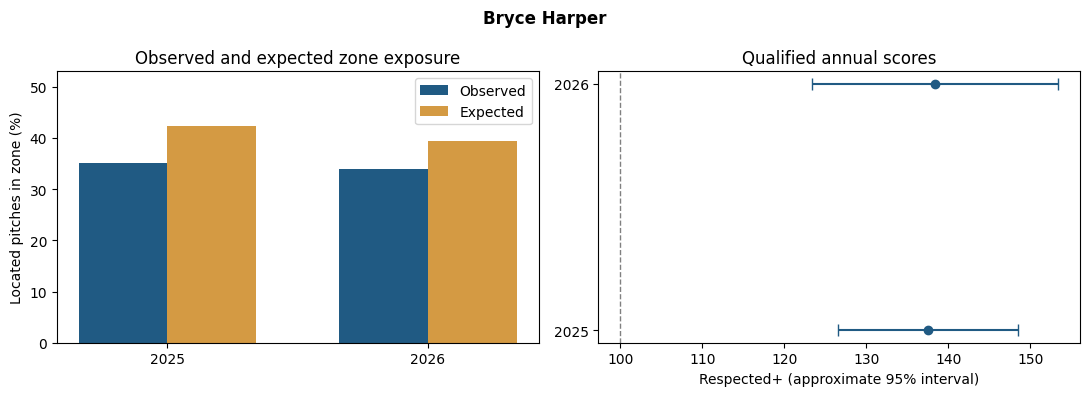

In [11]:
if PLAYER_ID is not None:
    player = report.loc[report.MLB_ID.eq(int(PLAYER_ID))].copy()
else:
    player = report.loc[report.Player.str.casefold().eq(PLAYER_NAME.casefold())].copy()
if player.empty:
    raise ValueError('Player not found. Use an exact name from report or set PLAYER_ID.')
if player.MLB_ID.nunique() != 1:
    raise ValueError('Multiple player IDs match this name; set PLAYER_ID.')
player = player.sort_values('Season')
print(player.Player.iloc[0])
display(player.round(2).reset_index(drop=True))
player_figure, axes = plt.subplots(1, 2, figsize=(11, 4))
pos = np.arange(len(player))
axes[0].bar(pos - 0.17, player.Zone_pct, width=0.34, label='Observed', color='#205a83')
axes[0].bar(pos + 0.17, player.Expected_zone_pct, width=0.34, label='Expected', color='#d49a43')
axes[0].set(
    xticks=pos,
    xticklabels=player.Season.astype(str),
    ylabel='Located pitches in zone (%)',
    title='Observed and expected zone exposure',
)
axes[0].set_ylim(0, 1.25 * max(player.Zone_pct.max(), player.Expected_zone_pct.max()))
axes[0].legend()
qualified_player = player.loc[player.Qualified & player.Respected_plus.notna()]
if not qualified_player.empty:
    axes[1].errorbar(
        qualified_player.Respected_plus,
        qualified_player.Season.astype(str),
        xerr=np.vstack(
            [
                (qualified_player.Respected_plus - qualified_player.Score_lo).clip(lower=0),
                (qualified_player.Score_hi - qualified_player.Respected_plus).clip(lower=0),
            ]
        ),
        fmt='o',
        capsize=4,
        color='#205a83',
    )
else:
    axes[1].text(0.5, 0.5, 'No qualified season', ha='center', transform=axes[1].transAxes)
axes[1].axvline(100, color='gray', linestyle='--', linewidth=1)
axes[1].set(xlabel='Respected+ (approximate 95% interval)', title='Qualified annual scores')
player_figure.suptitle(player.Player.iloc[0], fontweight='bold')
player_figure.tight_layout()
plt.show()

In [12]:
validation_summary = pd.DataFrame(
    [
        {
            'Season': int(season),
            'Model': model,
            'Pitches': int(g.n.sum()),
            'Brier': np.average(g.brier, weights=g.n),
            'Log_loss': np.average(g.log_loss, weights=g.n),
        }
        for (season, model), g in retro_validation.groupby(['season', 'model'])
    ]
)
display(validation_summary.round(6))

,Season,Model,Pitches,Brier,Log_loss
0,2025,retrospective_context,708367,0.237119,0.666686
1,2025,retrospective_count_only,708367,0.237705,0.667914
2,2025,retrospective_league,708367,0.243015,0.679111
3,2026,retrospective_context,712242,0.230788,0.653503
4,2026,retrospective_count_only,712242,0.231349,0.654702
5,2026,retrospective_league,712242,0.236416,0.665727


In [13]:
persistence_all_pairs = persistence_pairs(retro_scored, retro_board, estimate_effect)
persistence_metrics, persistence_differences = evaluate_persistence(
    persistence_all_pairs, PERSIST_BOOTSTRAPS
)
persistence_primary = persistence_metrics.query(
    "min_pitches == 300 and target == 'target_adjusted'"
)
persistence_primary_deltas = persistence_differences.query(
    "min_pitches == 300 and target == 'target_adjusted'"
)
display(
    persistence_primary[['n', 'predictor', 'spearman', 'ci_lo', 'ci_hi']]
    .round(4)
    .reset_index(drop=True)
)
display(
    persistence_primary_deltas[['adjusted', 'baseline', 'delta_spearman', 'ci_lo', 'ci_hi']]
    .round(4)
    .reset_index(drop=True)
)
delta = persistence_primary_deltas.query(
    "adjusted == 'adjusted_shrunk' and baseline == 'raw_zone'"
).iloc[0]
if delta.ci_lo <= 0 <= delta.ci_hi:
    print(
        'This test does not establish a Respected+ ranking advantage over raw zone rate; it does not prove equivalence.'
    )
else:
    print(
        'The conditional paired interval excludes zero. Interpret this single transition with the limits above.'
    )

,n,predictor,spearman,ci_lo,ci_hi
0,379,adjusted_shrunk,0.4562,0.3712,0.5316
1,379,adjusted_unshrunk,0.4438,0.3565,0.5217
2,379,raw_zone,0.4545,0.3701,0.5316
3,379,raw_shrunk,0.4648,0.3803,0.5394


,adjusted,baseline,delta_spearman,ci_lo,ci_hi
0,adjusted_shrunk,raw_zone,0.0016,-0.0277,0.0316
1,adjusted_shrunk,raw_shrunk,-0.0087,-0.0347,0.0177
2,adjusted_unshrunk,raw_zone,-0.0107,-0.0379,0.0160
3,adjusted_unshrunk,raw_shrunk,-0.0210,-0.0497,0.0073


This test does not establish a Respected+ ranking advantage over raw zone rate; it does not prove equivalence.


In [14]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
report.to_csv(OUTPUT_DIR / 'respected_plus_hitter_report.csv', index=False)
player.to_csv(OUTPUT_DIR / 'selected_player_report.csv', index=False)
player_figure.savefig(OUTPUT_DIR / 'selected_player_report.png', dpi=180, bbox_inches='tight')
retro_board.to_csv(OUTPUT_DIR / 'model_hitter_estimates.csv', index=False)
retro_scored.to_parquet(OUTPUT_DIR / 'held_out_pitch_predictions.parquet', index=False)
coverage.to_csv(OUTPUT_DIR / 'source_coverage.csv', index=False)
validation_summary.to_csv(OUTPUT_DIR / 'validation_summary.csv', index=False)
retro_provenance.to_csv(OUTPUT_DIR / 'fold_provenance.csv', index=False)
retro_tuning.to_csv(OUTPUT_DIR / 'nested_tuning.csv', index=False)
retro_game_assignments.to_csv(OUTPUT_DIR / 'game_assignments.csv', index=False)
persistence_all_pairs.to_csv(OUTPUT_DIR / 'hitter_year_pairs.csv', index=False)
persistence_metrics.to_csv(OUTPUT_DIR / 'persistence_metrics.csv', index=False)
persistence_differences.to_csv(OUTPUT_DIR / 'paired_correlation_differences.csv', index=False)
with open(OUTPUT_DIR / 'run_manifest.json', 'w') as f:
    json.dump(
        {
            'notebook': 'Respected_Plus_MLB_Final',
            'model_baseline': 'V4 unchanged',
            'mode': 'full_season_retrospective_game_held_out',
            'source_file': DATA_FILE_OVERRIDE,
            'source_date_window': [START_DATE, END_DATE],
            'required_seasons': list(REQUIRED_SEASONS),
            'coverage_reference_as_of': COVERAGE_REFERENCE_AS_OF,
            'zone_half_width_ft': ZONE_HALF_WIDTH,
            'qualification': [MIN_SCORED_PITCHES, MIN_SCORED_PA],
            'folds': RETRO_OUTER_FOLDS,
            'C_grid': list(RETRO_C_GRID),
            'seed': RETRO_RANDOM_SEED,
            'max_train': RETRO_MAX_TRAIN,
            'inner_max_train': RETRO_INNER_MAX_TRAIN,
            'bootstrap_repetitions': PERSIST_BOOTSTRAPS,
            'intervals': 'conditional; omit model fitting and shared pitcher/game uncertainty',
        },
        f,
        indent=2,
    )
print('Saved results to:', OUTPUT_DIR.resolve())

Saved results to: C:\Users\brend\Downloads\respected_mlb_final_results
